# Actividad: importancia de variables y matriz de consistencia

**Predicción de la carga de primera falla en estructuras pantográficas mediante regresión, ingeniería de características y SHAP**

**Universidad Nacional de Ingeniería · Maestría en Inteligencia Artificial · Trabajo de Investigación II · sección B · 2026-II**  
**Docente:** Glen Dario Rodríguez Rafael  
**Alumna:** Melissa Dessire Aylas Barranca

La investigación examina la relación predictiva entre la geometría previa al ensayo y la carga experimental de primera falla de estructuras pantográficas. Se comparan las variables originales con descriptores geométricos derivados mediante regresión Ridge y Elastic Net. La evaluación separa el efecto de la representación de los datos del efecto del ajuste de hiperparámetros, y utiliza predicciones obtenidas fuera de los conjuntos de entrenamiento.

La importancia de variables se estudia mediante SHAP, permutación y ablación; cada método responde a una propiedad distinta del modelo. La matriz de consistencia presenta problemas de investigación con objetivos e hipótesis contrastables, variables e indicadores verificables. Los resultados se interpretan como evidencia predictiva exploratoria de 26 casos, sin atribuir causalidad mecánica a los valores SHAP.

## 1. Importancia predictiva de las variables geométricas

### 1.1 Variable de respuesta y conjuntos de entrada

Se estima la carga de primera falla [N] con características geométricas conocidas antes del ensayo. El identificador del caso y las respuestas posteriores se excluyen de los predictores.

| Conjunto | Composición | Función en la comparación |
|---|---|---|
| **A** | Diez variables originales de fibras, pivotes, volúmenes y celdas. | Referencia geométrica. |
| **B** | A más los momentos de sección b·h³/12 y h·b³/12 [mm⁴]. | Evaluar el aporte de dos descriptores derivados. |

La razón logarítmica de volúmenes (C) y la reducción de variables redundantes (D) pertenecen al análisis exploratorio anterior; no forman parte del ajuste principal de esta sección.

In [1]:
from pathlib import Path
import json
import sys
import warnings
warnings.filterwarnings('ignore', message='IProgress not found.*')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / "config" / "ajuste_modelos.json").is_file():
    ROOT = ROOT.parent
assert (ROOT / "config" / "ajuste_modelos.json").is_file(), "Ubique el notebook dentro de este repositorio."
sys.path.insert(0, str(ROOT))
from src.ajuste_modelos import load_frozen_data, load_outer_splits, inner_splits
from src.feature_engineering import TARGET, MOMENTS, LOG_RATIO, make_pipeline, feature_names, nominal_groups
from src.transformaciones_eda import GEOMETRY, geometry_features
from src.figuras_importancia import LABELS

OUT = ROOT / "reports" / "feature_importance"
TABLES, FIGURES = OUT / "tables", OUT / "figures"
config = json.loads((ROOT / "config/ajuste_modelos.json").read_text(encoding="utf-8"))
frame = load_frozen_data(ROOT)
splits, groups, records = load_outer_splits(frame, ROOT)
X, y = frame[GEOMETRY], frame[TARGET]
assert config["target"] == TARGET == "First_Failure_Load_N" and config["target_unit"] == "N"
assert not set(GEOMETRY) & {TARGET, "Case_n", "Ultimate_Load", "Maximum_Displacement"}


<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación.</strong> Con Ridge fijo y validación por configuración, B redujo el MAE de 13,2466 a 12,8346 N frente a A. La mejora fue pequeña (0,4119 N) y desapareció al reservar familias completas. Como los momentos se calculan a partir de dimensiones ya incluidas en A, su utilidad requiere un contraste con las mismas particiones y parámetros.</p>
</div>

### 1.2 Modelos y diseño de validación

La comparación se organiza en pares que mantienen constante la familia de regresión, los parámetros y las particiones externas cuando se evalúa el efecto de las características. El ajuste de hiperparámetros se realiza después, exclusivamente con datos del entrenamiento externo.

| Experimento | Modelo | Variables de entrada | Parámetros | Contraste principal |
|---|---|---|---|---|
| E0 | Mediana del entrenamiento | A | Sin ajuste | Referencia ingenua |
| E1 / E2 | Ridge | A / B | α = 1; solver SVD | Efecto de los momentos con parámetros fijos |
| E3 / E4 | Ridge | B / A | α seleccionado en validación interna | Efecto del ajuste y contraste A/B bajo ajuste equivalente |
| S1 / S2 | Elastic Net | A / B | α = 0,1; proporción L1 = 0,5 | Efecto de los momentos en una segunda familia de modelos |
| S3 / S4 | Elastic Net | B / A | α y proporción L1 seleccionados internamente | Contraste A/B bajo ajuste equivalente |

La evaluación externa deja fuera, por separado, cada una de las 24 configuraciones nominales. Una segunda evaluación reserva cada una de las tres familias definidas por el número de celdas en Y. Dentro de cada entrenamiento externo, la selección de hiperparámetros emplea particiones agrupadas. La imputación, la eliminación de atributos constantes y el escalamiento se ajustan dentro del <em>pipeline</em> correspondiente, sin utilizar el conjunto externo reservado.

In [2]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error

train, test = splits["configuracion"][0]
cv_inner = inner_splits(frame, train, "configuracion")
ridge_b = make_pipeline("B")
grid_ridge = config["modelos"]["Ridge"]["grid"]
assert not set(frame.iloc[train].Case_n) & set(frame.iloc[test].Case_n)
assert all(not set(inner_train) & set(inner_test) for inner_train, inner_test in cv_inner)

demo = GridSearchCV(ridge_b, grid_ridge, cv=cv_inner,
                    scoring="neg_mean_absolute_error", refit=True,
                    error_score="raise", n_jobs=1)
demo.fit(X.iloc[train], y.iloc[train])
pred_demo = demo.predict(X.iloc[test])
assert len(feature_names(demo.best_estimator_)) == demo.best_estimator_.named_steps["model"].coef_.size
display(pd.DataFrame([{"α seleccionado en entrenamiento": demo.best_params_["model__alpha"],
                       "Caso reservado": frame.iloc[test].Case_n.tolist(),
                       "Carga observada [N]": y.iloc[test].tolist(),
                       "Carga estimada [N]": pred_demo.tolist(),
                       "MAE de la partición externa [N]": mean_absolute_error(y.iloc[test], pred_demo)}]))

,α seleccionado en entrenamiento,Caso reservado,Carga observada [N],Carga estimada [N],MAE de la partición externa [N]
0,0.0001,[5],[59.68],[70.49680097982099],10.816801


### 1.3 Ejecución reproducible de las comparaciones

La ejecución reproduce E0–E4 y S1–S4 en ambos esquemas de validación. El conjunto de datos y las particiones conservan sus huellas SHA-256; la semilla, los espacios de búsqueda y los parámetros seleccionados se registran por partición. Las tablas reúnen predicciones fuera de entrenamiento, métricas, contribuciones SHAP, importancias por permutación y resultados de ablación. Las figuras se generan a partir de esas mismas tablas.

In [3]:
from src.sprint_importancia import run as run_sprint
from src.figuras_importancia import run as run_figures
from time import sleep

manifest = run_sprint(ROOT)
for attempt in range(6):
    try:
        figure_names = run_figures(ROOT)
        break
    except OSError:
        if attempt == 5:
            raise
        sleep(5)  # Windows puede retener transitoriamente un PNG/SVG recién abierto.
assert manifest["n_casos"] == 26 and len(figure_names) == 16
assert manifest["dataset_sha256"] == config["dataset_sha256"]
assert manifest["particiones_sha256"] == config["particiones_sha256"]
def tabla(nombre):
    return pd.read_csv(TABLES / f"{nombre}.csv")
def figura(numero):
    paths = sorted(FIGURES.glob(f"{numero:02d}_*.png"))
    assert len(paths) == 1, (numero, paths)
    display(Image(filename=str(paths[0]), width=900))


### 1.4 Desempeño predictivo antes y después de la ingeniería de características

El MAE es la métrica principal del plan de tesis. Se añaden el error cuadrático medio (MSE, N²), su raíz (RMSE, N) y R² para hacer visible el cambio al pasar de A a B y el efecto posterior del ajuste de hiperparámetros. El MSE se calcula como RMSE² sobre las mismas predicciones externas; no constituye una evaluación adicional ni una métrica de importancia de variables.

In [4]:
metricas = tabla("metricas_resumen")
pred = tabla("predicciones_oof")
busquedas = tabla("busquedas")
etapas = {"E0": "Mediana de entrenamiento", "E1": "A · parámetros fijos",
          "E2": "B · parámetros fijos", "E3": "B · ajuste interno",
          "E4": "A · ajuste interno"}
resumen = metricas[metricas.protocolo.eq("configuracion") &
                  metricas.experimento.isin(etapas)].copy()
resumen["Comparación"] = resumen.experimento.map(etapas)
resumen["MSE_N2"] = resumen.RMSE_N ** 2
resumen["Orden"] = resumen.experimento.map({e: i for i, e in enumerate(etapas)})
resumen = resumen.sort_values("Orden")
display(resumen[["Comparación", "MAE_N", "MSE_N2", "RMSE_N", "R2_OOF"]]
        .rename(columns={"MAE_N": "MAE [N]", "MSE_N2": "MSE [N²]",
                         "RMSE_N": "RMSE [N]", "R2_OOF": "R² externo"}).round(3))
assert all(pred.groupby(["protocolo", "experimento"]).Case_n.nunique() == 26)
recalc = pred.groupby(["protocolo", "experimento"]).apply(
    lambda g: np.mean(np.abs(g.observado_N - g.predicho_N)), include_groups=False)
assert all(np.isclose(metricas.set_index(["protocolo", "experimento"]).MAE_N, recalc))

,Comparación,MAE [N],MSE [N²],RMSE [N],R² externo
0,Mediana de entrenamiento,49.748,4185.965,64.699,-0.213
1,A · parámetros fijos,13.247,267.183,16.346,0.923
2,B · parámetros fijos,12.835,262.533,16.203,0.924
3,B · ajuste interno,10.981,207.307,14.398,0.940
4,A · ajuste interno,9.707,152.049,12.331,0.956


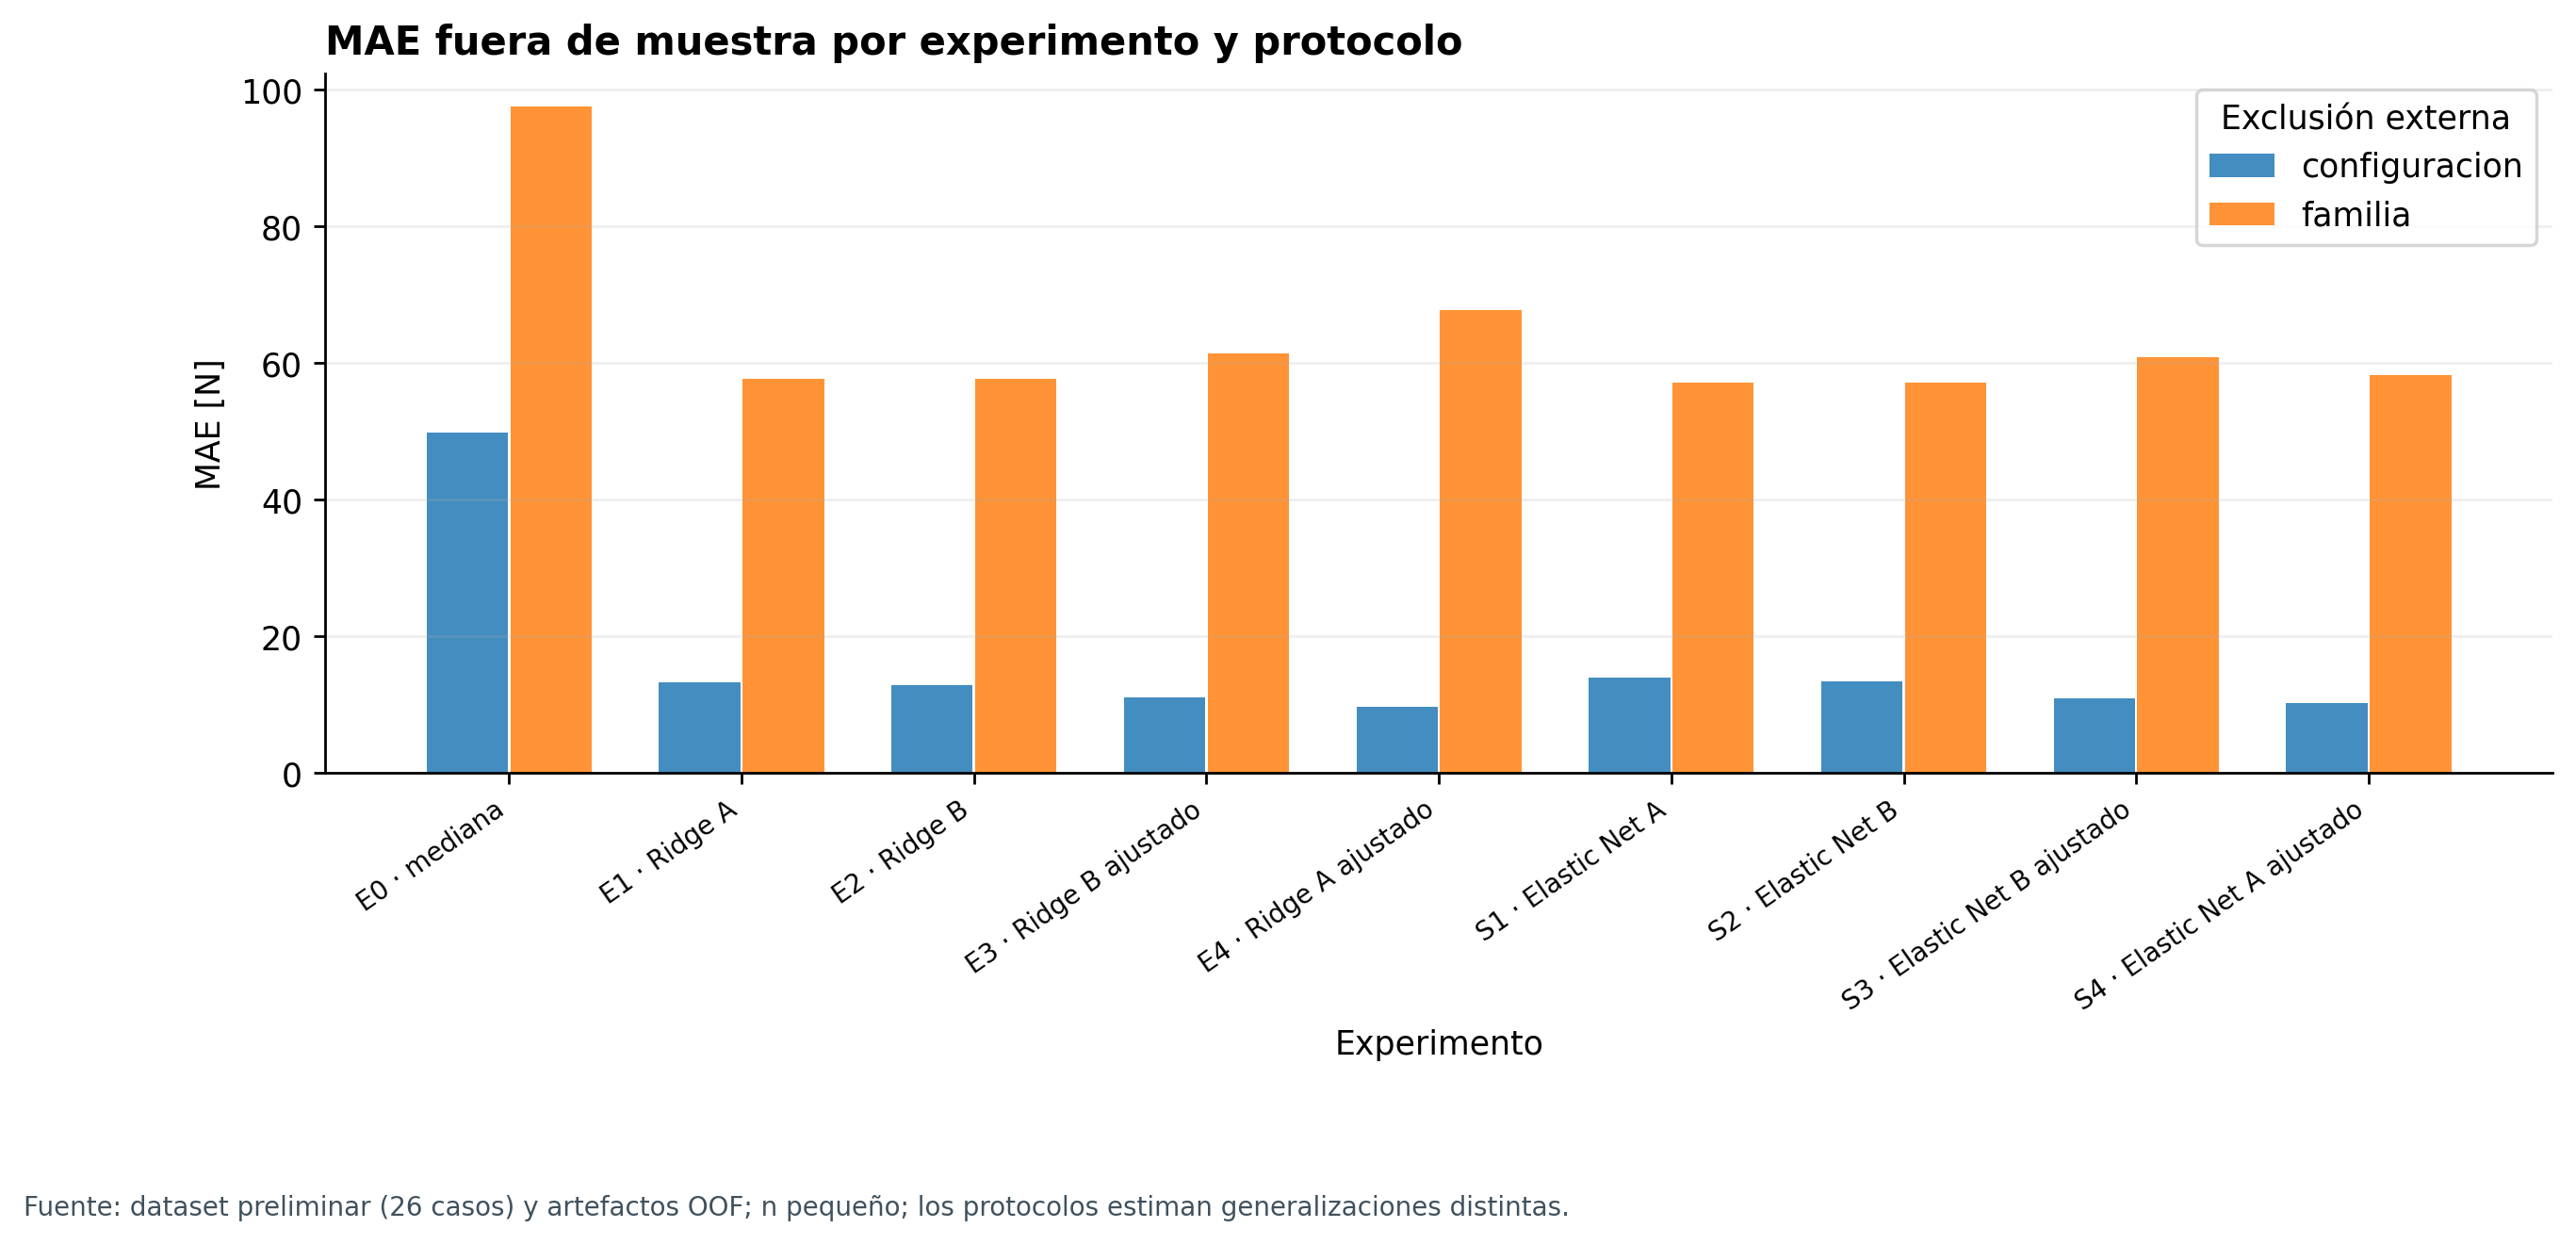

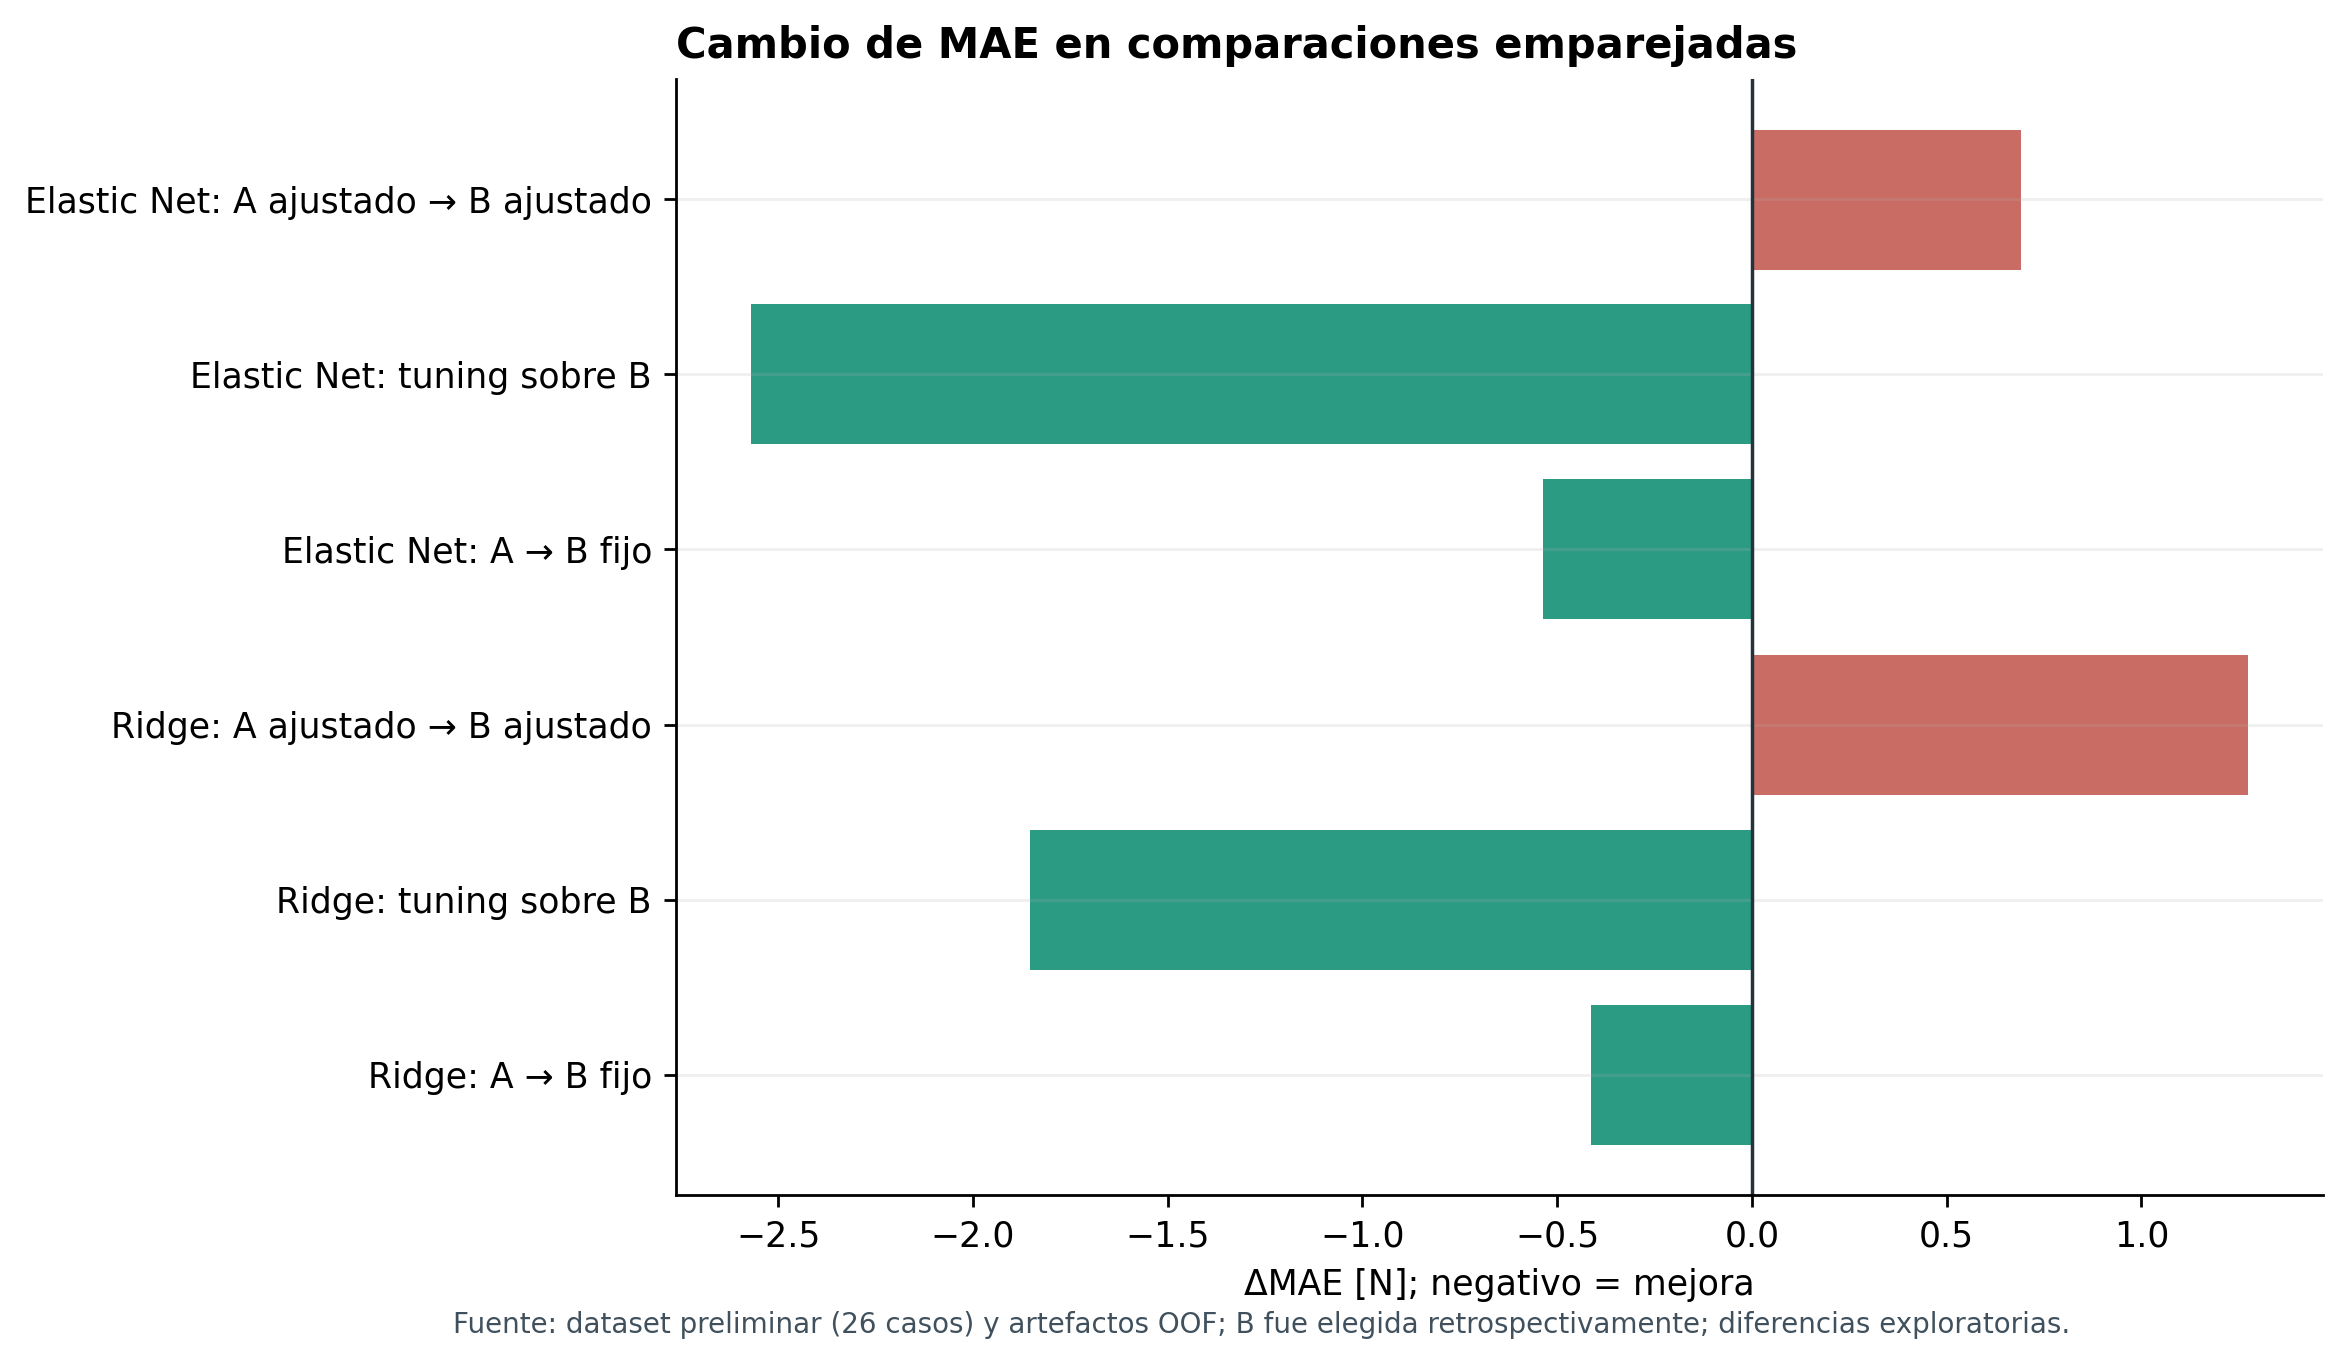

In [5]:
figura(1)
figura(2)

<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación.</strong> Al añadir los momentos con parámetros fijos (E1→E2), el MAE pasa de 13,247 a 12,835 N; el MSE, de 267,183 a 262,533 N²; y el RMSE, de 16,346 a 16,203 N. El ajuste interno de B (E3) reduce el RMSE a 14,398 N. No obstante, A ajustado con el mismo protocolo (E4) registra el menor error: MAE de 9,707 N, MSE de 152,049 N² y RMSE de 12,331 N.</p>
<p>Por tanto, la ventaja pequeña de B con parámetros fijos no se conserva tras el ajuste equivalente. La importancia de variables se interpreta a continuación sobre modelos cuya precisión ya fue evaluada; calcular SHAP por sí mismo no modifica el MSE ni el RMSE. La validación que deja fuera familias completas presenta errores mucho mayores y R² negativos, por lo que estos resultados describen principalmente la predicción de nuevas configuraciones dentro de las familias observadas.</p>
</div>

#### 1.4.1 Sensibilidad al tamaño de entrenamiento

Una curva de aprendizaje agrupada complementa la evaluación externa. Para Ridge fijo con A, se calculan MAE de entrenamiento y validación con 10, 15 y 20 observaciones de entrenamiento. Este análisis describe la sensibilidad al tamaño muestral y no interviene en la selección del modelo ni sustituye la validación externa por configuración o familia.

,Casos de entrenamiento,MAE de entrenamiento [N],MAE de validación [N],Desv. MAE de validación [N]
0,10,9.806,19.557,6.721
1,15,10.878,19.187,6.657
2,20,10.108,14.410,5.648


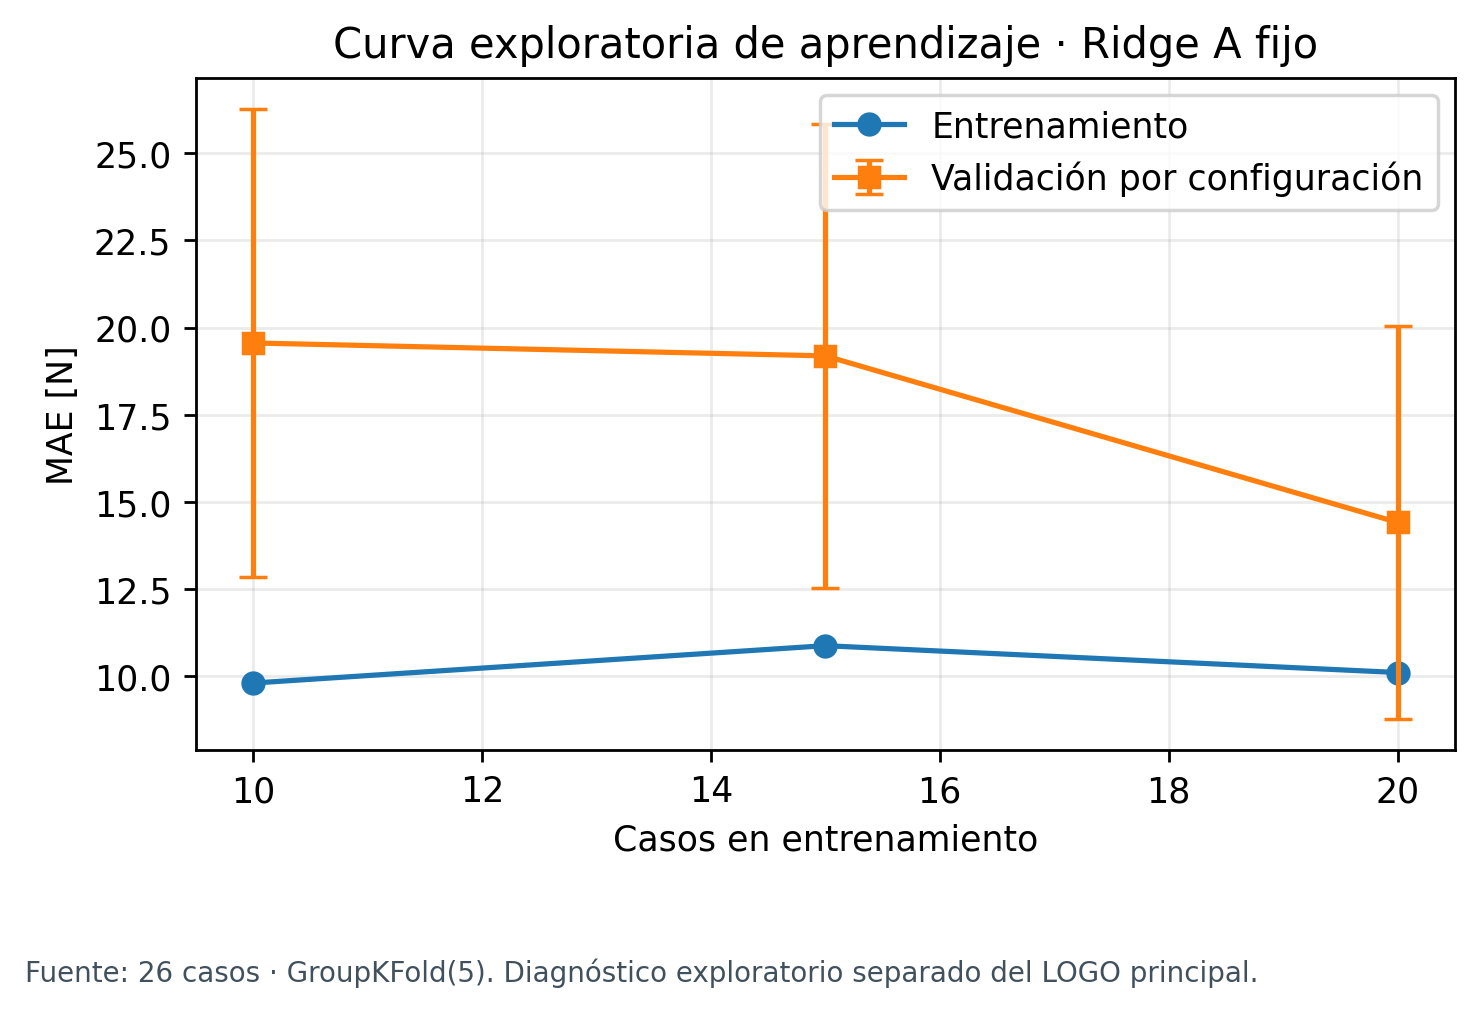

In [6]:
from sklearn.model_selection import GroupKFold, learning_curve
nominal = nominal_groups(frame, config["group_columns"])
sizes, train_scores, val_scores = learning_curve(
    make_pipeline("A"), X, y, groups=nominal, cv=GroupKFold(n_splits=5),
    train_sizes=[0.5, 0.75, 1.0], shuffle=True, random_state=42,
    scoring="neg_mean_absolute_error", n_jobs=1)
aprendizaje = pd.DataFrame({"Casos de entrenamiento": sizes, "MAE de entrenamiento [N]": -train_scores.mean(axis=1),
                           "MAE de validación [N]": -val_scores.mean(axis=1),
                           "Desv. MAE de validación [N]": val_scores.std(axis=1, ddof=1)})
display(aprendizaje.round(3))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(sizes, -train_scores.mean(axis=1), marker="o", label="Entrenamiento")
ax.errorbar(sizes, -val_scores.mean(axis=1), yerr=val_scores.std(axis=1, ddof=1),
            marker="s", capsize=4, label="Validación por configuración")
ax.set(title="Curva exploratoria de aprendizaje · Ridge A fijo",
       xlabel="Casos en entrenamiento", ylabel="MAE [N]")
ax.grid(alpha=0.25); ax.legend(loc="upper right")
fig.text(0.02, 0.02, "Fuente: 26 casos · GroupKFold(5). Diagnóstico exploratorio separado del LOGO principal.",
         fontsize=8, color="#40515d")
fig.subplots_adjust(bottom=0.24)
fig.savefig(FIGURES / "17_curva_aprendizaje.png", dpi=250, bbox_inches="tight", facecolor="white")
fig.savefig(FIGURES / "17_curva_aprendizaje.svg", bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=str(FIGURES / "17_curva_aprendizaje.png"), width=850))

<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación de los resultados.</strong></p>
<p>El MAE medio de validación disminuye de 19,56 N con 10 casos de entrenamiento a 14,41 N con 20. La dispersión entre particiones permanece cercana a 5 N en el tamaño mayor. La tendencia sugiere que disponer de más ensayos podría reducir el error, pero tres tamaños y 26 casos no permiten estimar una curva de saturación ni cuantificar con precisión la ganancia esperada de una nueva campaña experimental.</p>
</div>

### 1.5 Distribución de residuales y errores individuales

Se define el residual como carga observada menos carga estimada, en newtons. La inspección de predicciones externas permite examinar sesgo, dispersión y casos de error elevado. Las figuras de observado frente a estimado y de residuales corresponden a Ridge ajustado con B (E3); se presenta además la tabla de los mayores errores de Ridge ajustado con A (E4), que obtuvo el menor MAE agregado.

,MAE [N],Error máximo [N],Sesgo observado − estimado [N],Desv. de residuales [N]
Experimento,,,,
E3,10.981,42.297,0.168,14.682
E4,9.707,30.280,0.307,12.571
S3,10.872,42.250,-0.295,14.443
S4,10.180,30.254,0.266,12.875


,Caso,Familia Y,Observado [N],Estimado [N],Residual [N],Error absoluto [N]
49,1,4,47.55,77.83,-30.28,30.28
58,4,4,86.45,61.72,24.73,24.73
94,17,5,75.71,97.55,-21.84,21.84
22,3,4,88.50,69.19,19.31,19.31
130,10,5,114.30,97.02,17.28,17.28


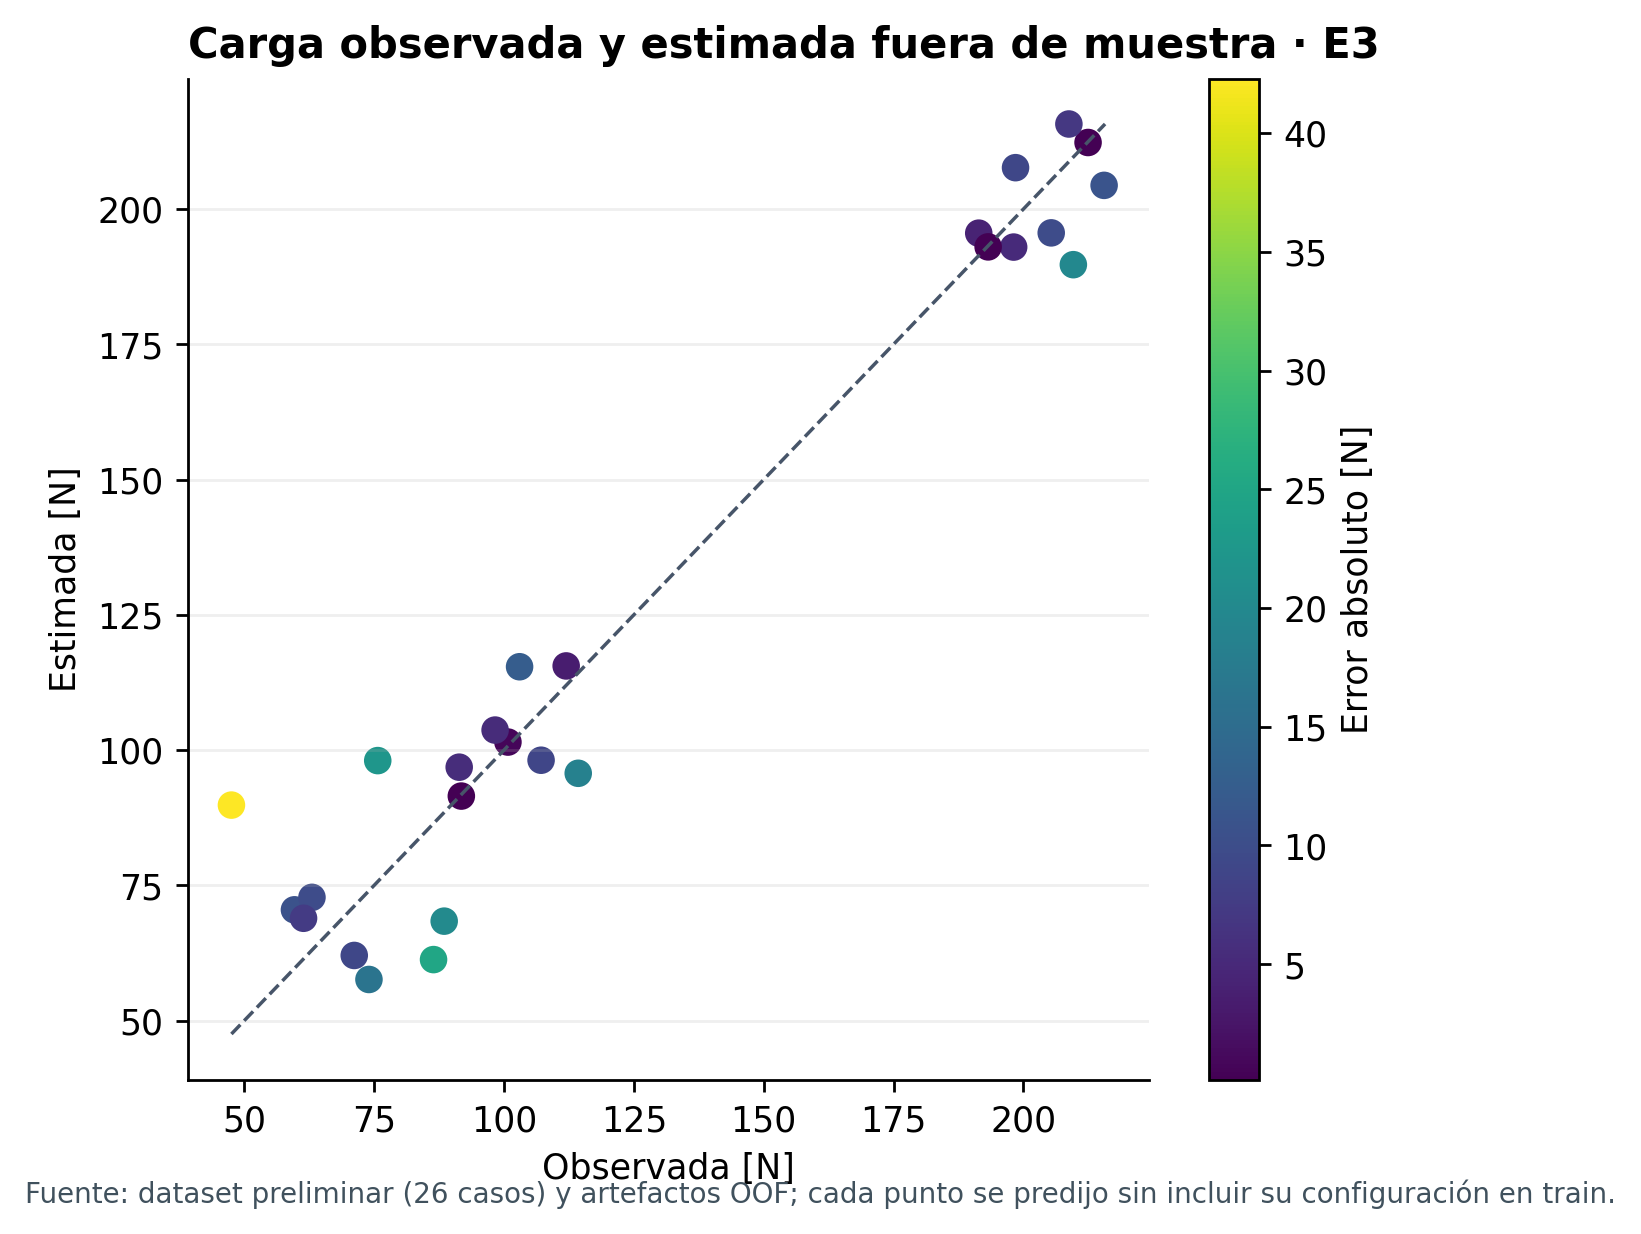

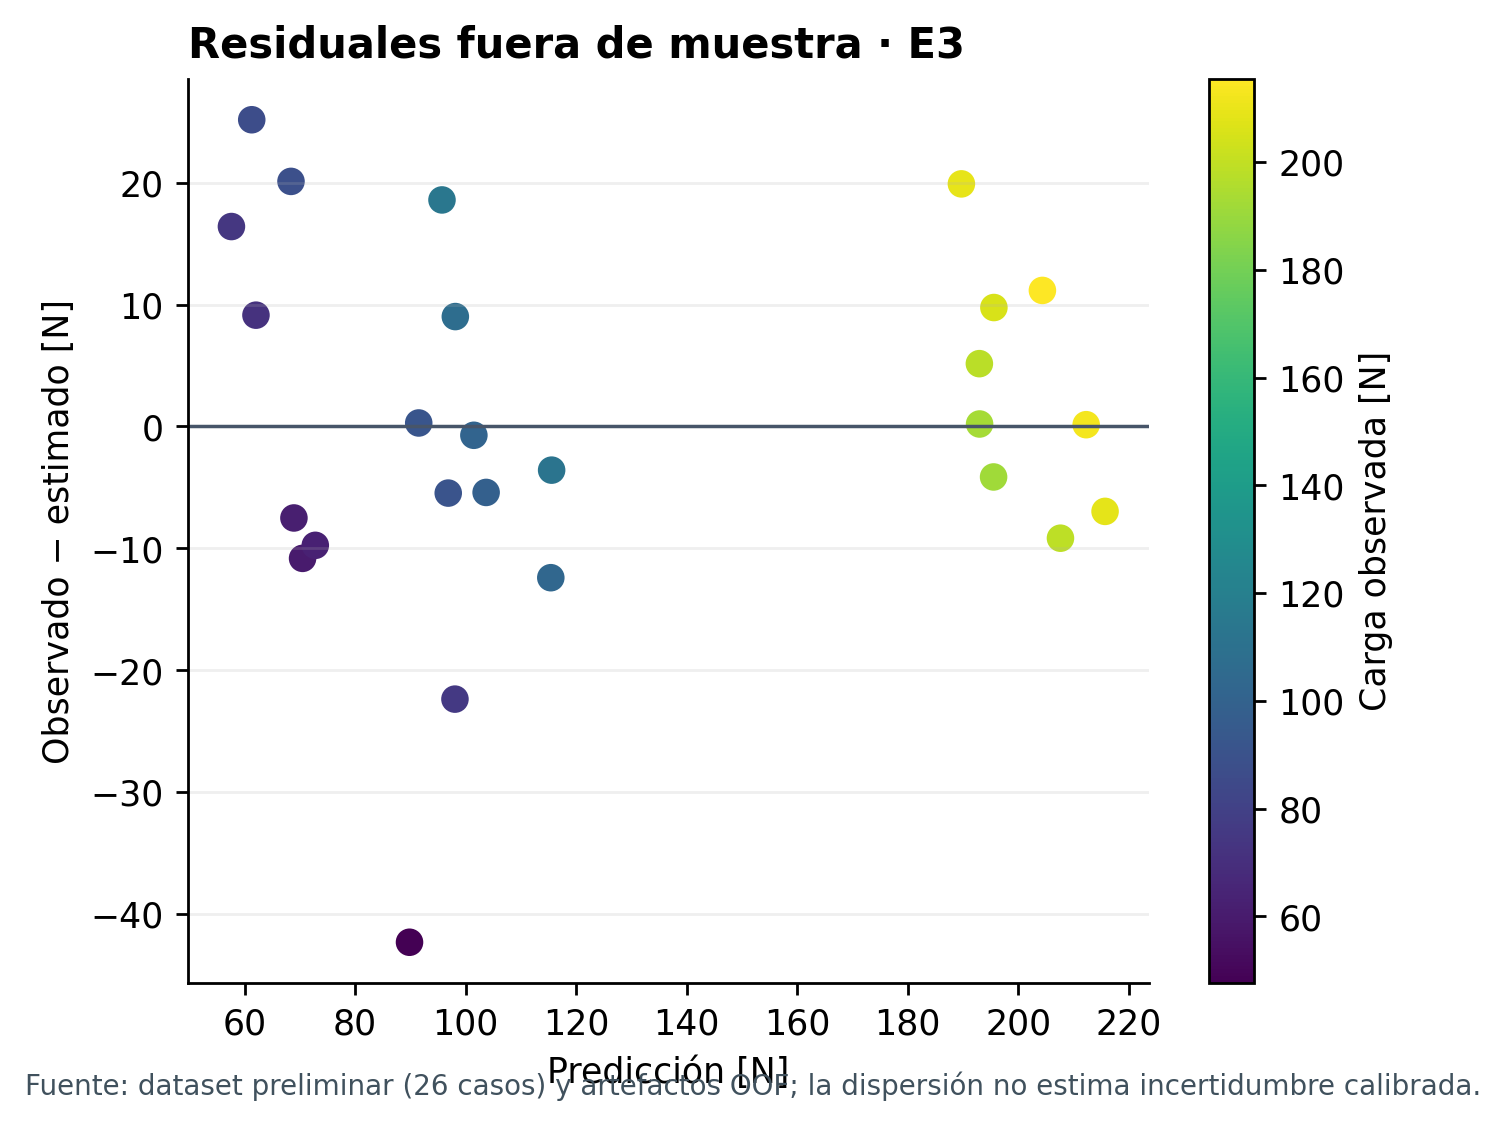

In [7]:
diag = pred[pred.protocolo.eq("configuracion") & pred.experimento.isin(["E3", "E4", "S3", "S4"])].copy()
diag["error_abs_N"] = (diag.observado_N - diag.predicho_N).abs()
resumen_residuales = diag.groupby("experimento").agg(
    MAE_N=("error_abs_N", "mean"),
    max_error_N=("error_abs_N", "max"),
    sesgo_observado_menos_predicho_N=("residuo_N", "mean"),
    SD_residuo_N=("residuo_N", "std"))
display(resumen_residuales.rename_axis("Experimento").rename(columns={
    "MAE_N": "MAE [N]", "max_error_N": "Error máximo [N]",
    "sesgo_observado_menos_predicho_N": "Sesgo observado − estimado [N]",
    "SD_residuo_N": "Desv. de residuales [N]"}).round(3))
display(diag[diag.experimento.eq("E4")].nlargest(5, "error_abs_N")
        [["Case_n", "familia", "observado_N", "predicho_N", "residuo_N", "error_abs_N"]]
        .rename(columns={"Case_n": "Caso", "familia": "Familia Y",
                         "observado_N": "Observado [N]", "predicho_N": "Estimado [N]",
                         "residuo_N": "Residual [N]", "error_abs_N": "Error absoluto [N]"}).round(2))
figura(3)
figura(4)

In [8]:
familia_error = (pred[pred.protocolo.eq("familia") & pred.experimento.isin(["E1", "E3", "E4", "S1", "S2", "S3", "S4"])]
                 .groupby(["experimento", "familia"])
                 .error_absoluto_N.agg(["count", "mean", "max"]).reset_index())
display(familia_error.pivot(index="familia", columns="experimento", values="mean")
        .rename_axis(index="Familia Y", columns="Experimento").round(2))

Experimento,E1,E3,E4,S1,S2,S3,S4
Familia Y,,,,,,,
4,55.40,23.83,45.03,55.27,53.41,53.39,49.76
5,41.59,41.23,40.80,41.01,42.61,43.21,40.44
6,75.67,114.82,114.95,74.85,74.86,84.99,83.50


<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación de los resultados.</strong></p>
<p>El menor error agregado de E4 no elimina fallas individuales: el caso 1 presenta una sobreestimación de 30,28 N (77,83 N estimados frente a 47,55 N observados), mientras el caso 4 presenta una subestimación de 24,73 N. El sesgo medio de E4 es cercano a cero (0,31 N para observado menos estimado), resultado compatible con errores de signos opuestos que se compensan en el promedio.</p>
<p>La reserva de familias Y produce errores mucho mayores que la reserva de configuraciones nominales. Las relaciones aprendidas dentro de las familias observadas no se transfieren con fiabilidad a una arquitectura Y ausente del entrenamiento.</p>
</div>

### 1.6 Importancia de variables mediante SHAP

Las explicaciones SHAP se calculan para observaciones excluidas del ajuste del modelo que las predice. Ridge y Elastic Net se interpretan con <code>shap.LinearExplainer</code> sobre las características transformadas en cada partición. El conjunto de referencia procede únicamente del entrenamiento externo; el objetivo no se transforma, de modo que el valor base, las contribuciones y la predicción conservan la unidad de newtons.

El explicador utiliza un <code>masker.Independent</code>. Sus perturbaciones no preservan necesariamente las relaciones de dependencia entre descriptores geométricos; por ello, las atribuciones individuales deben leerse como propiedades del modelo y del conjunto de referencia, no como efectos mecánicos aislados. La identidad entre predicción, valor base y suma de contribuciones se comprueba numéricamente en una partición externa.

In [9]:
import shap
selected = busquedas[(busquedas.protocolo.eq("configuracion")) &
                     (busquedas.experimento.eq("E3")) &
                     (busquedas.fold.eq(1)) &
                     (busquedas.selected.astype(str).str.lower().eq("true"))].iloc[0]
alpha = json.loads(selected.params_json)["model__alpha"]
modelo_explicado = make_pipeline("B", alpha=alpha).fit(X.iloc[train], y.iloc[train])
z_train = np.asarray(modelo_explicado[:-1].transform(X.iloc[train]), dtype=float)
z_test = np.asarray(modelo_explicado[:-1].transform(X.iloc[test]), dtype=float)
nombres = feature_names(modelo_explicado).tolist()
assert z_train.shape[1] == z_test.shape[1] == len(nombres)
explainer = shap.LinearExplainer(modelo_explicado.named_steps["model"],
                                shap.maskers.Independent(z_train, max_samples=len(train)))
explanation = explainer(z_test)
prediction = modelo_explicado.predict(X.iloc[test])
reconstructed = np.asarray(explanation.base_values).reshape(-1) + explanation.values.sum(axis=1)
assert np.allclose(reconstructed, prediction, atol=1e-6)

#### 1.6.1 Magnitud global de las contribuciones

La importancia global se resume con la media del valor absoluto de SHAP, expresada en newtons. Esta magnitud indica cuánto contribuye una variable a desplazar las predicciones del modelo respecto de su valor base. La comparación considera Ridge con A ajustado (E4), Ridge con B ajustado (E3) y Elastic Net con B ajustado (S3); sus diferencias de desempeño proporcionan el contexto necesario para interpretar los rankings.

In [10]:
shap_oof = tabla("shap_oof")
shap_global = tabla("shap_global")
global_top = (shap_global[shap_global.protocolo.eq("configuracion") &
                          shap_global.experimento.isin(["E4", "E3", "S3"])]
              .sort_values(["experimento", "rank_global"])
              .groupby("experimento").head(6))
global_top = global_top.assign(Variable=global_top.feature.map(lambda f: LABELS.get(f, f)))
display(global_top[["experimento", "Variable", "mean_abs_shap_N",
                    "sd_fold_mean_abs_shap_N", "top3_fold_fraction", "mean_signed_shap_N"]]
        .rename(columns={"experimento":"Modelo", "mean_abs_shap_N":"Importancia SHAP media [N]",
                         "sd_fold_mean_abs_shap_N":"Desv. entre particiones [N]",
                         "top3_fold_fraction":"Fracción top 3",
                         "mean_signed_shap_N":"Media con signo [N]"}).round(3))


,Modelo,Variable,Importancia SHAP media [N],Desv. entre particiones [N],Fracción top 3,Media con signo [N]
27,E3,Número total de pivotes [conteo],102.889,92.734,0.708,20.255
30,E3,Número de celdas en Y [conteo],62.908,72.416,0.292,-20.540
22,E3,Longitud total de fibras [mm],34.039,23.175,0.583,1.100
29,E3,Volumen declarado del espécimen [mm³],23.678,14.227,0.458,0.324
25,E3,Momento de sección h·b³/12 [mm⁴],18.068,24.489,0.333,3.492
21,E3,Altura de sección de fibra [mm],16.986,13.940,0.250,-0.204
36,E4,Número total de pivotes [conteo],196.598,126.874,1.000,1.578
39,E4,Número de celdas en Y [conteo],153.697,110.880,1.000,-0.794
33,E4,Longitud total de fibras [mm],39.200,26.476,0.750,0.172
38,E4,Volumen declarado del espécimen [mm³],16.106,9.486,0.208,-0.318


<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación de los resultados.</strong></p>
<p>En E4, el número total de pivotes y el número de celdas en Y alcanzan medias absolutas SHAP de 196,60 y 153,70 N. En E3, las mismas variables alcanzan 102,89 y 62,91 N, seguidas por la longitud total de fibras (34,04 N). Elastic Net con B ajustado reduce la magnitud atribuida a pivotes a 66,31 N y sitúa después la longitud de fibras (30,69 N). Las diferencias entre modelos reflejan repartos distintos de información compartida y de regularización; las magnitudes SHAP no comparan directamente la precisión de los modelos.</p>
<p>E4 obtiene el menor MAE por configuración, aunque sus atribuciones individuales son mayores y más variables. La combinación de coeficientes de signo opuesto sobre predictores muy correlacionados puede producir contribuciones elevadas que se cancelan en la predicción final. Por tanto, una variable situada en primer lugar en el ranking no constituye por sí sola una explicación mecánica de la primera fractura.</p>
</div>

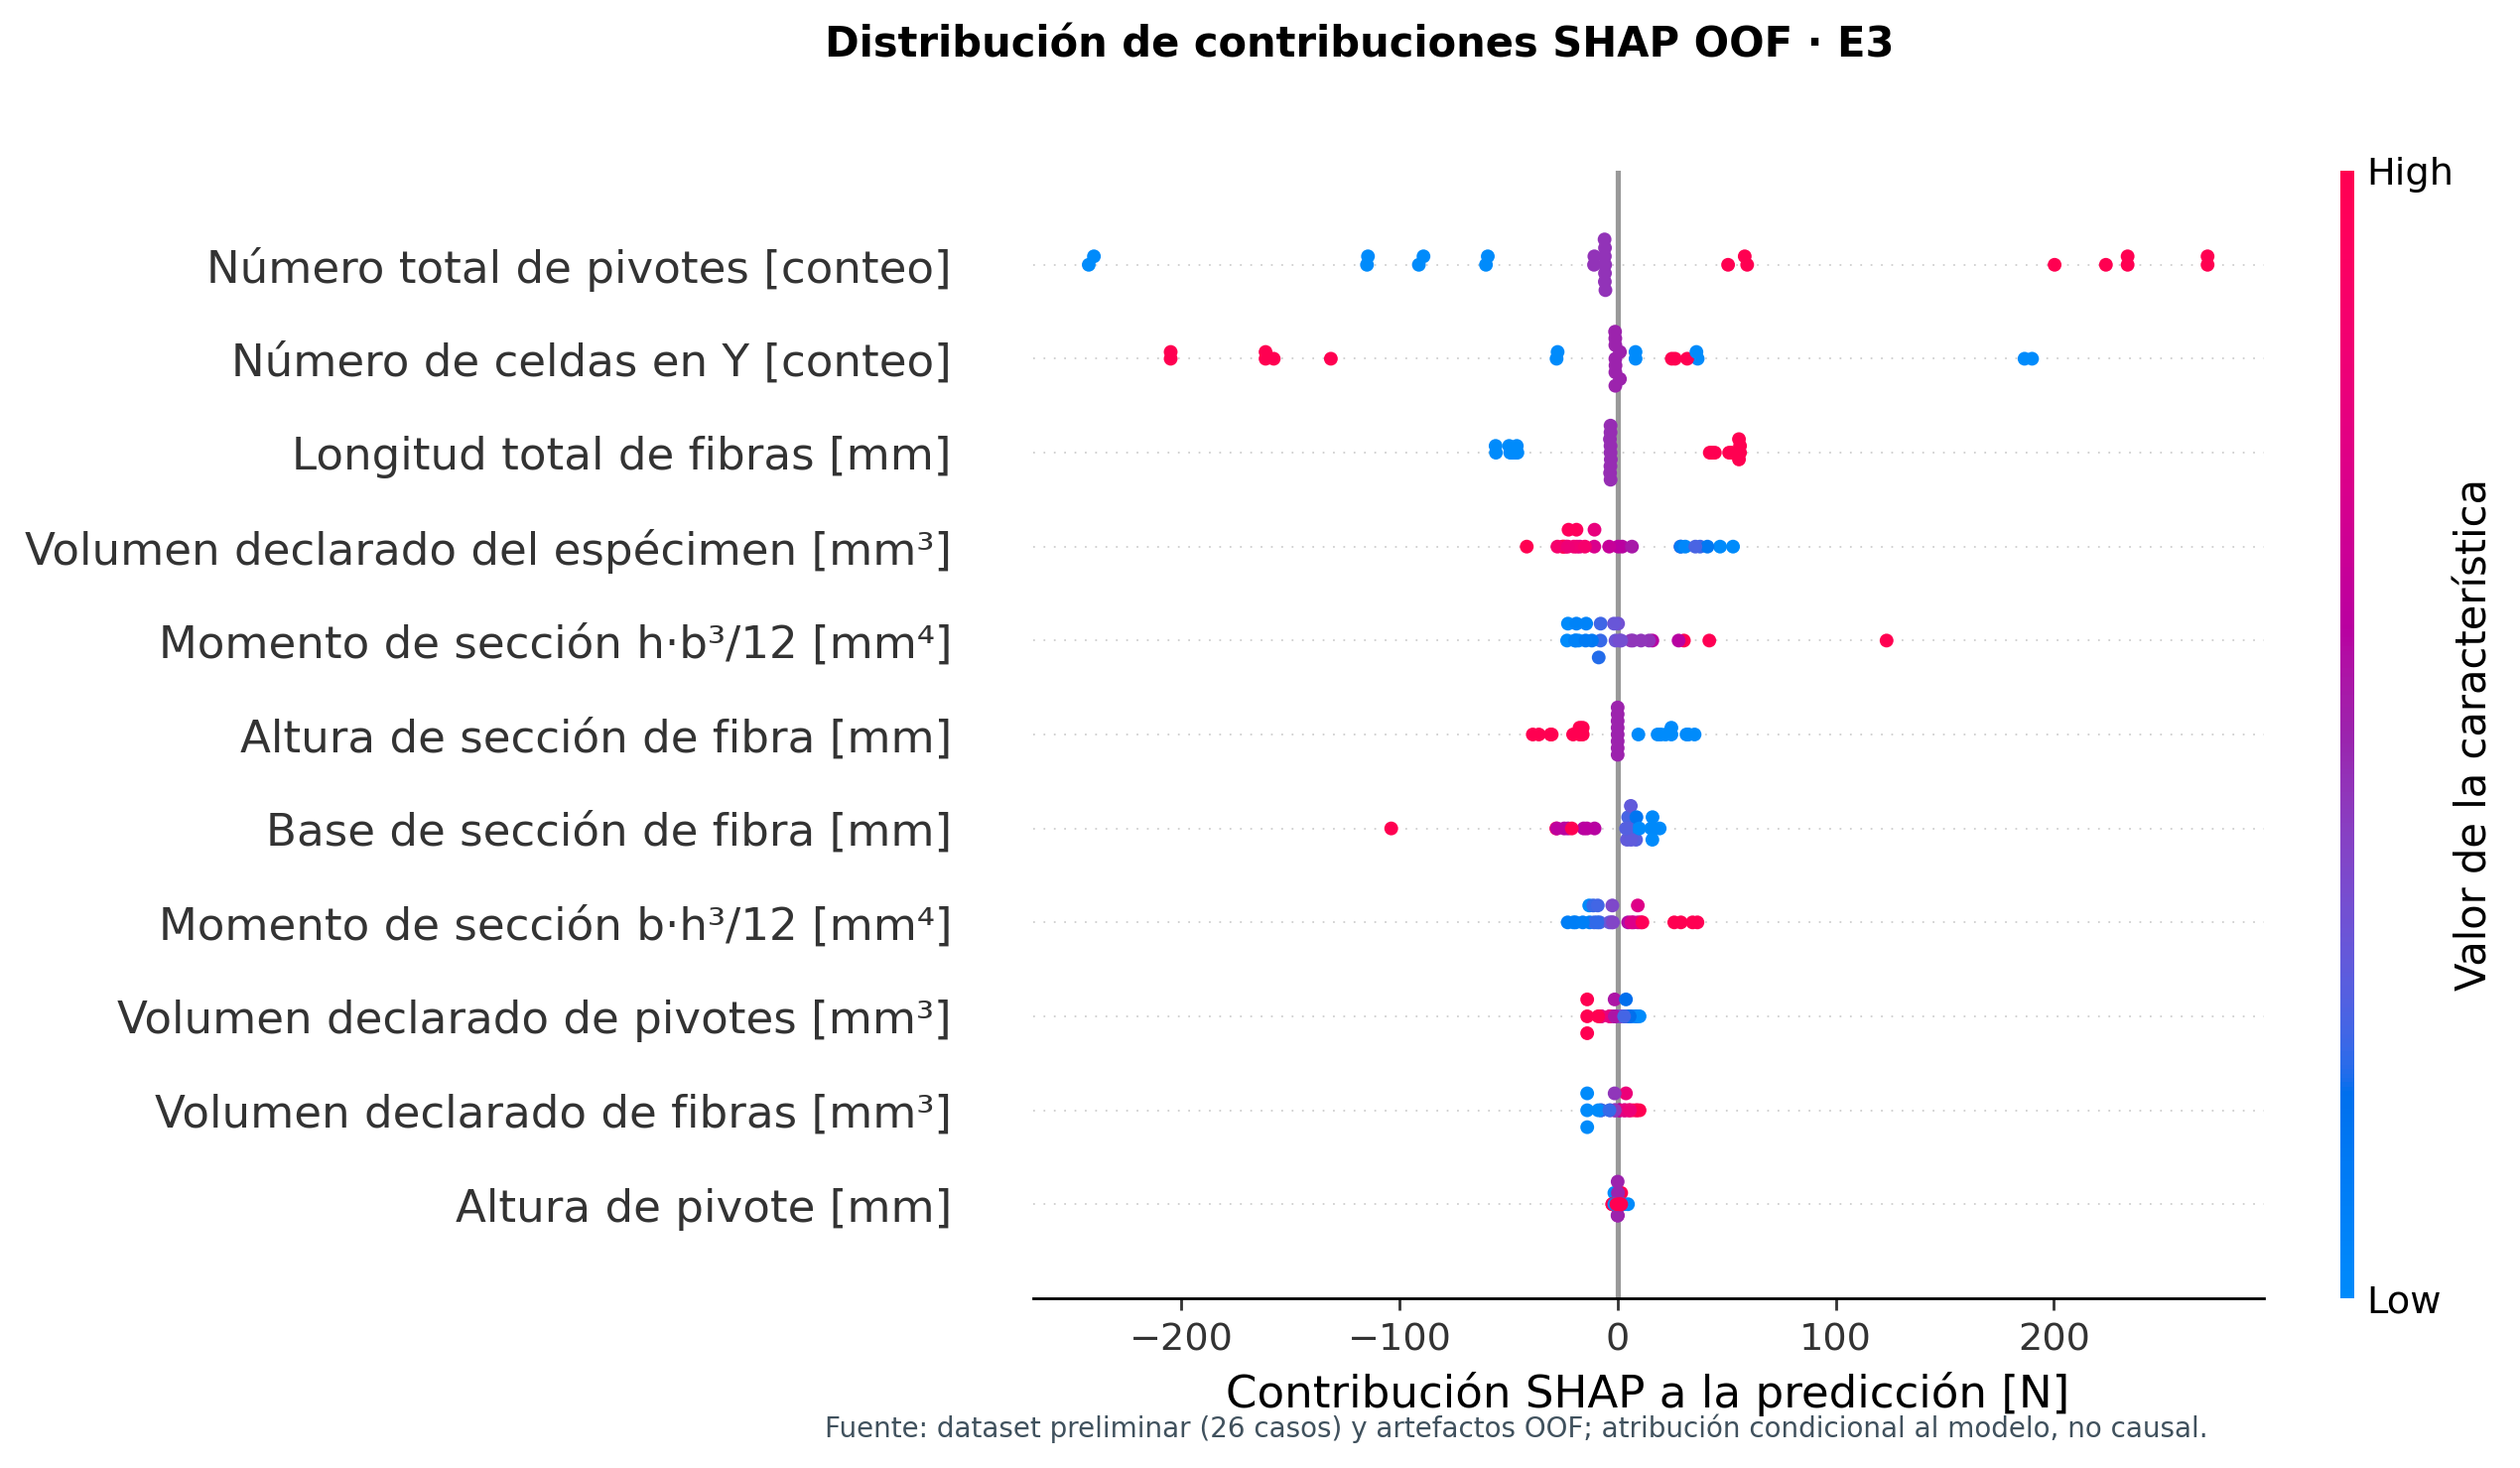

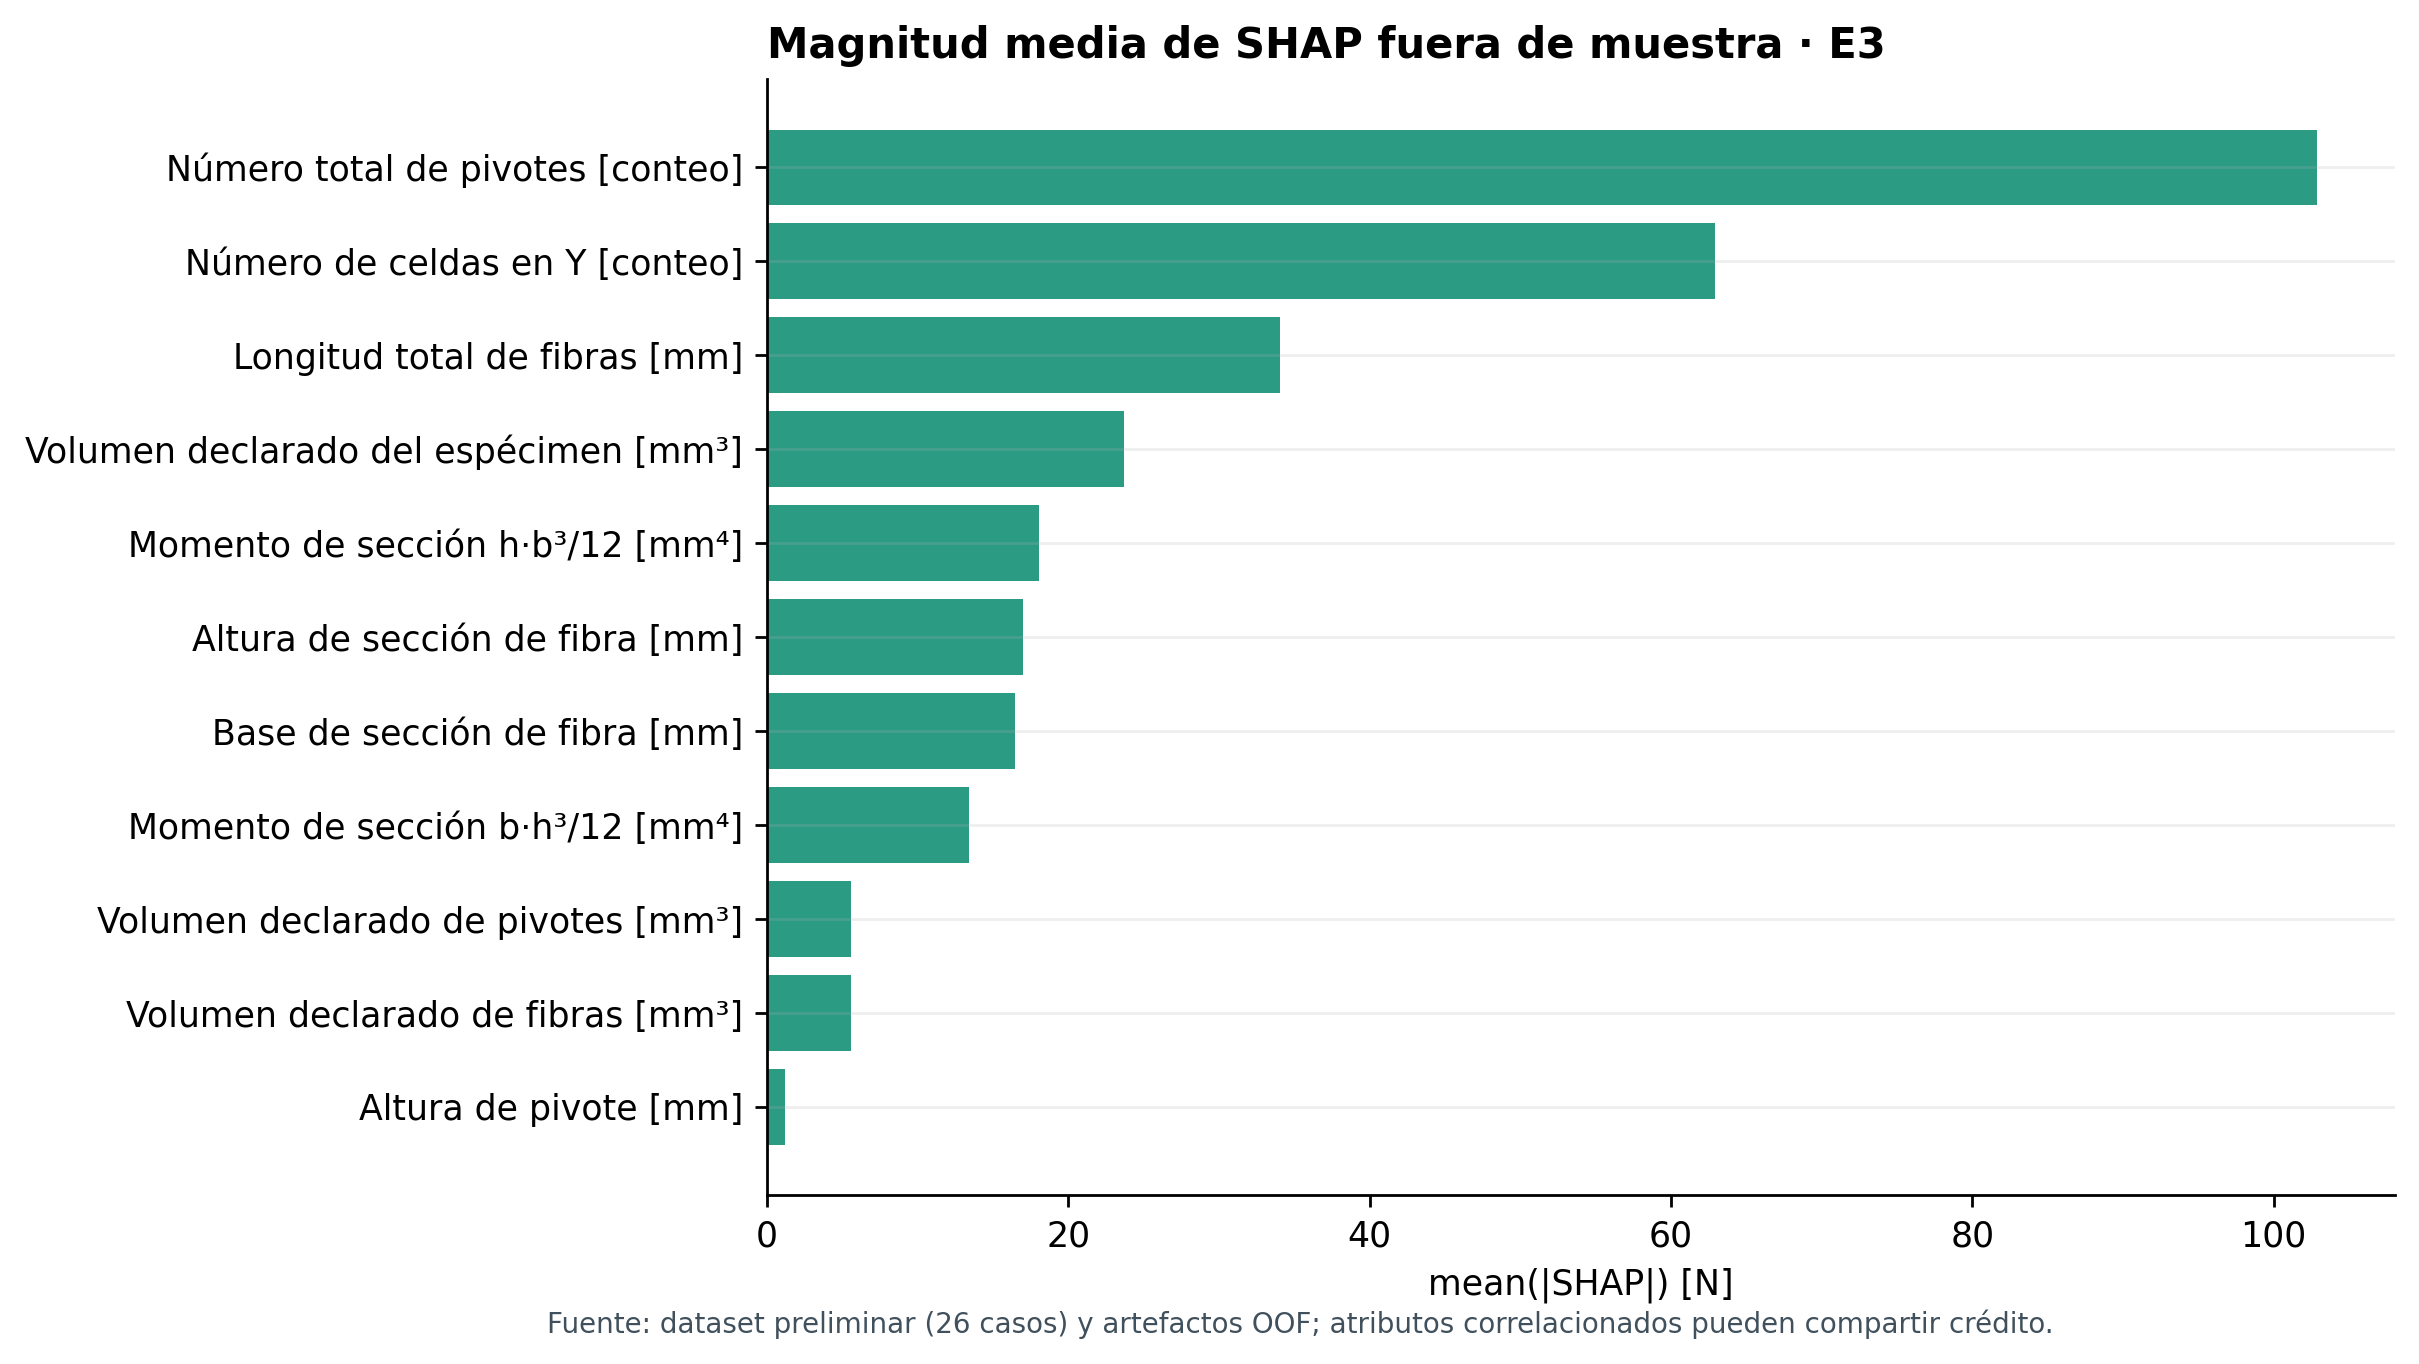

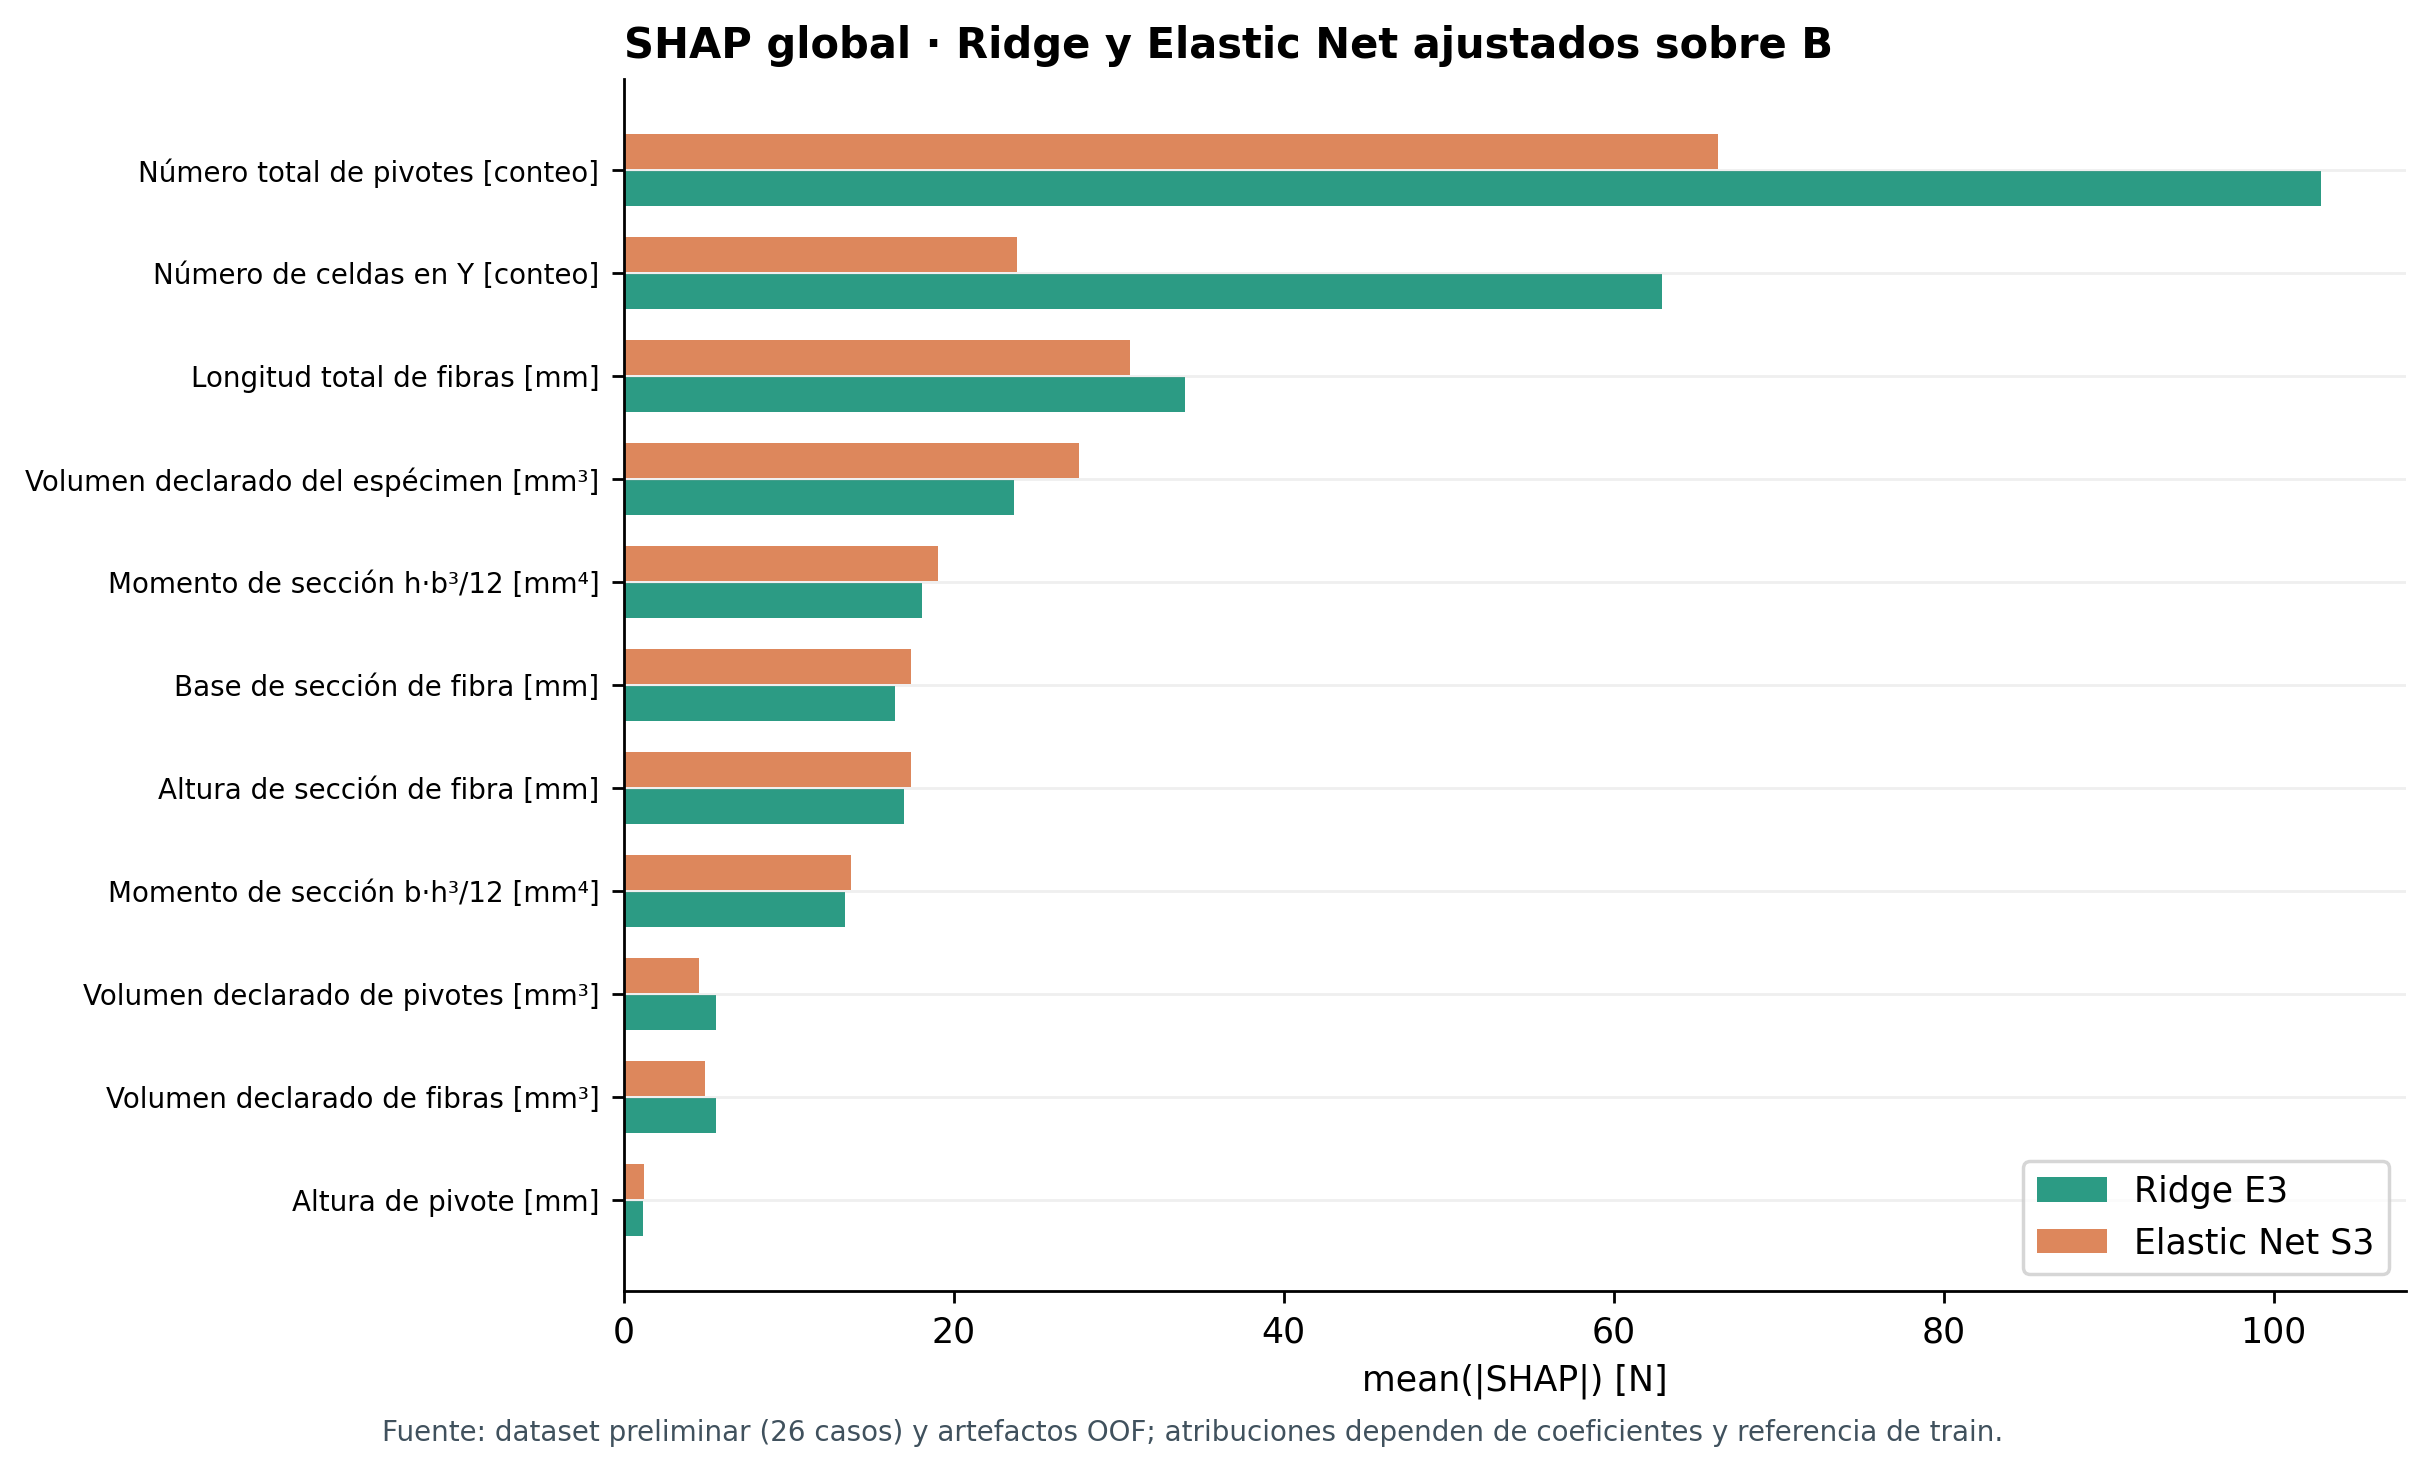

In [11]:
figura(5)  # beeswarm E3: distribución, signo y valor físico
figura(6)  # ranking E3
figura(10) # mismo B ajustado: Ridge frente a Elastic Net

#### 1.6.2 Estabilidad entre particiones y dirección de las contribuciones

La estabilidad se examina mediante la frecuencia con la que cada variable aparece entre las cinco primeras en las particiones externas, la dispersión de su magnitud SHAP y el signo de los coeficientes estandarizados. El signo SHAP de un caso expresa un desplazamiento respecto del valor base de esa partición; no equivale al efecto marginal de modificar una dimensión física manteniendo las demás constantes.

,Modelo,Variable,Coeficiente medio [N/z],Desv. del coeficiente [N/z],Proporción de signo positivo
2,E3,Longitud total de fibras [mm],37.149,2.793,1.000
4,E3,Momento de sección b·h³/12 [mm⁴],14.318,4.193,1.000
5,E3,Momento de sección h·b³/12 [mm⁴],22.606,7.955,1.000
7,E3,Número total de pivotes [conteo],87.432,55.962,1.000
10,E3,Número de celdas en Y [conteo],-26.427,64.592,0.500
13,E4,Longitud total de fibras [mm],44.531,1.127,1.000
16,E4,Número total de pivotes [conteo],222.371,14.557,1.000
19,E4,Número de celdas en Y [conteo],-180.354,16.409,0.000
22,S3,Longitud total de fibras [mm],35.268,1.522,1.000
24,S3,Momento de sección b·h³/12 [mm⁴],14.872,3.831,1.000


,Modelo,Variable,Proporción en los cinco primeros,Posición mediana
7,E3,Número total de pivotes [conteo],0.875,1.0
10,E3,Número de celdas en Y [conteo],0.500,5.5
2,E3,Longitud total de fibras [mm],0.708,3.0
9,E3,Volumen declarado del espécimen [mm³],0.792,4.0
5,E3,Momento de sección h·b³/12 [mm⁴],0.750,5.0
16,E4,Número total de pivotes [conteo],1.000,1.0
19,E4,Número de celdas en Y [conteo],1.000,2.0
13,E4,Longitud total de fibras [mm],0.917,3.0
18,E4,Volumen declarado del espécimen [mm³],0.917,4.0
17,E4,Volumen declarado de pivotes [mm³],0.625,5.0


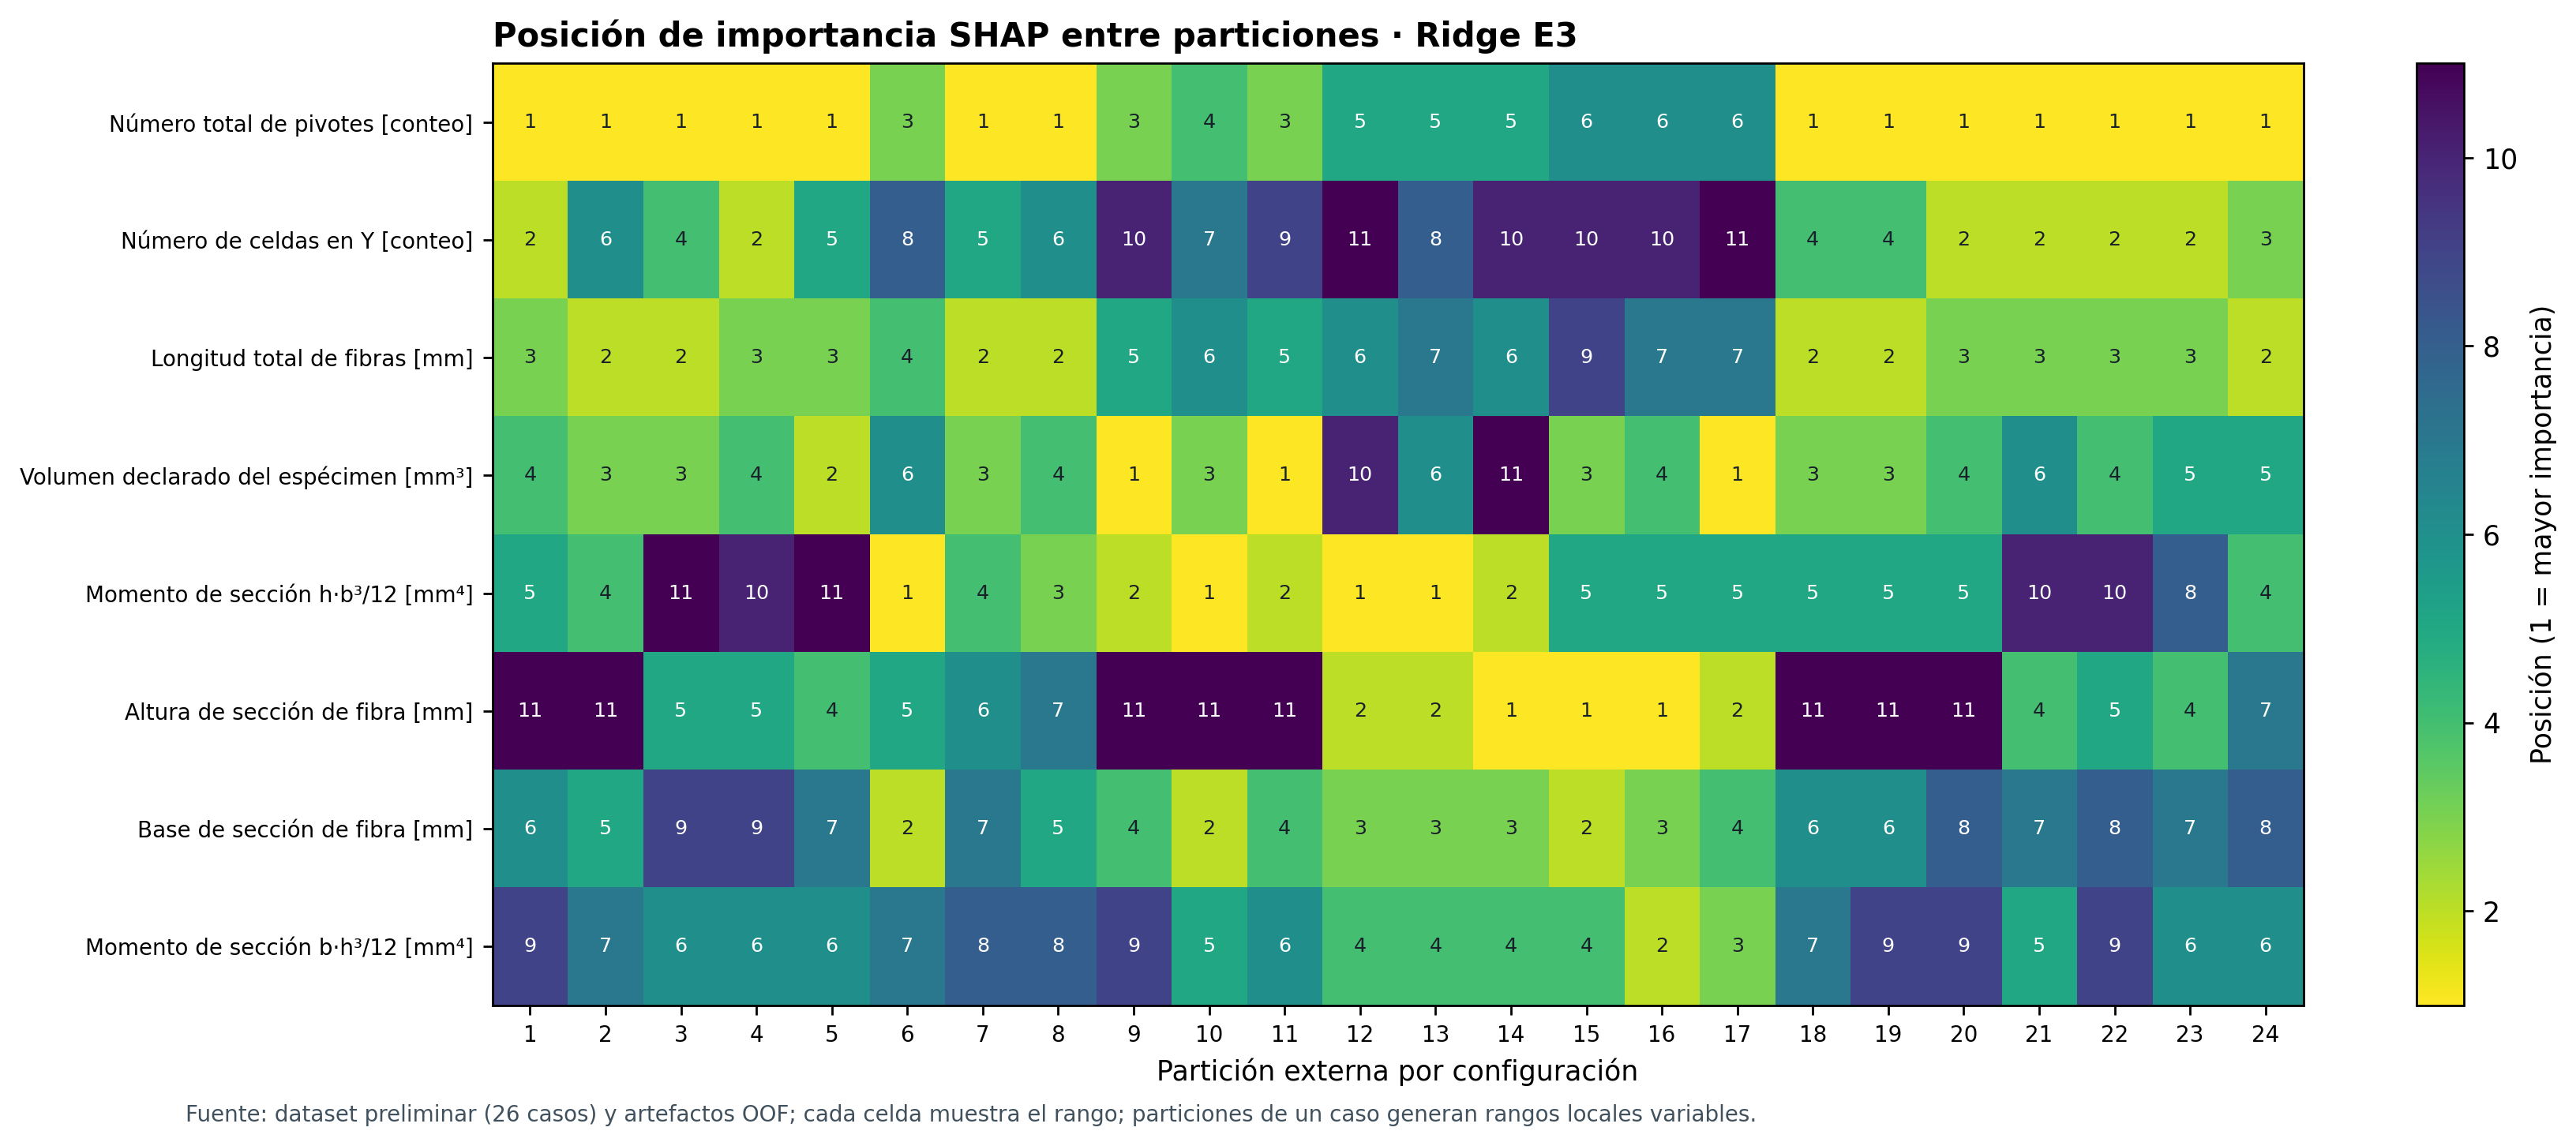

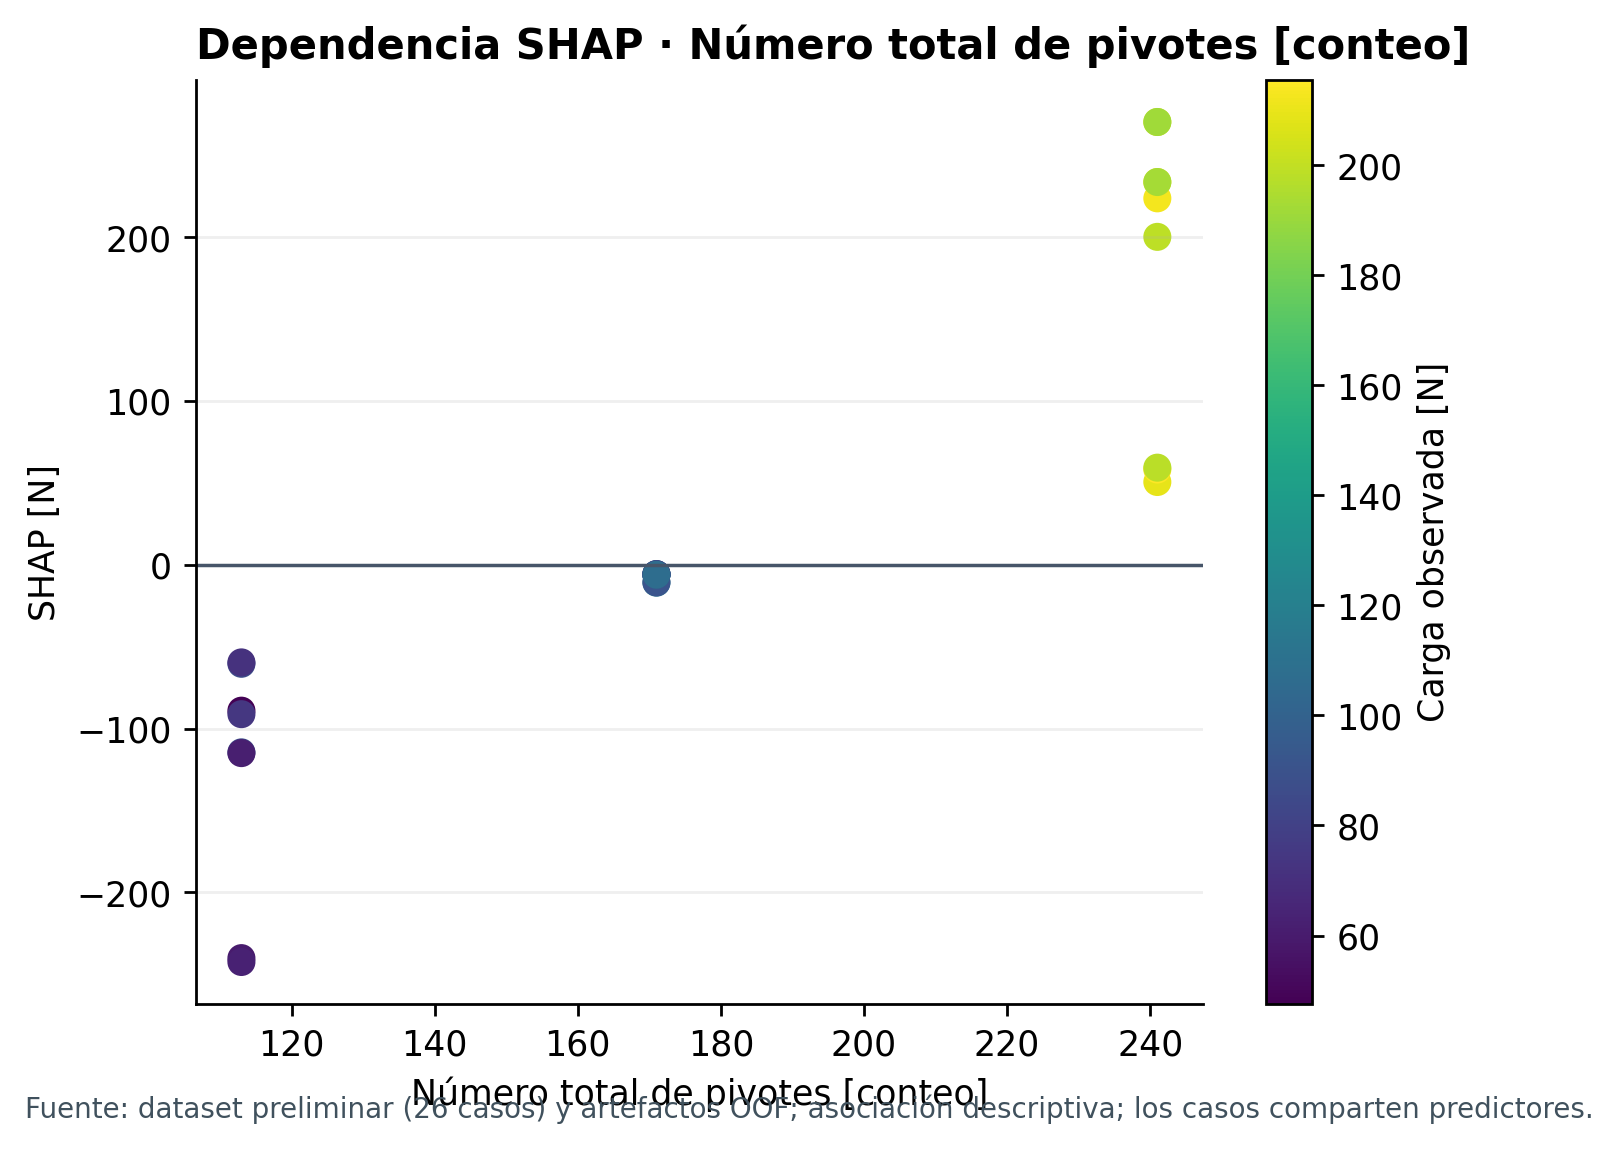

In [12]:
coef = tabla("coeficientes_folds")
signos = (coef[coef.protocolo.eq("configuracion") & coef.experimento.isin(["E3", "E4", "S3"])]
          .groupby(["experimento", "feature"])
          .coeficiente_por_z_N.agg(media="mean", desviacion="std",
                                   fraccion_positiva=lambda s: float((s > 0).mean()))
          .reset_index())
signos["Variable"] = signos.feature.map(lambda f: LABELS.get(f, f))
display(signos[signos.feature.isin(["Pivot_total_number", "n_cells_Y", "Fiber_total_length",
                                     "I_fibra_bh3_mm4", "I_fibra_hb3_mm4"])]
        [["experimento", "Variable", "media", "desviacion", "fraccion_positiva"]]
        .rename(columns={"experimento": "Modelo", "media": "Coeficiente medio [N/z]",
                         "desviacion": "Desv. del coeficiente [N/z]",
                         "fraccion_positiva": "Proporción de signo positivo"}).round(3))
estabilidad = tabla("shap_estabilidad")
top5 = (estabilidad[estabilidad.protocolo.eq("configuracion") &
                    estabilidad.experimento.isin(["E3", "E4", "S3"])]
        .groupby(["experimento", "feature"])
        .rank_fold.agg(fraccion_top5=lambda s: float((s <= 5).mean()),
                       rango_mediano="median").reset_index())
top5 = top5.merge(shap_global[["protocolo", "experimento", "feature", "rank_global"]]
                  .query("protocolo == 'configuracion'"),
                  on=["experimento", "feature"], validate="one_to_one")
top5["Variable"] = top5.feature.map(lambda f: LABELS.get(f, f))
display(top5.sort_values(["experimento", "rank_global"]).groupby("experimento").head(5)
        [["experimento", "Variable", "fraccion_top5", "rango_mediano"]]
        .rename(columns={"experimento": "Modelo", "fraccion_top5": "Proporción en los cinco primeros",
                         "rango_mediano": "Posición mediana"}).round(3))
figura(11)
figura(9)

<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación de los resultados.</strong></p>
<p>En E3, el número de pivotes figura entre las tres variables de mayor importancia en el 70,8 % de las particiones; su desviación de magnitud SHAP entre particiones es de 92,73 N. El número de celdas Y aparece entre las tres primeras solo en el 29,2 % y su desviación es de 72,42 N. En E4, ambas ocupan las primeras posiciones con frecuencia, aunque sus desviaciones aumentan hasta 126,87 y 110,88 N. La repetición de un rango alto no garantiza estabilidad de la magnitud atribuida cuando los predictores comparten casi toda su variación.</p>
</div>

#### 1.6.3 Explicaciones locales de observaciones experimentales

Se examinan cuatro predicciones de Ridge con B ajustado, todas obtenidas fuera del entrenamiento correspondiente: el caso 11, cercano a la mediana observada; el caso 1, de mayor error absoluto; el caso 22, de carga elevada; y el caso 5, de carga baja. La selección permite observar tanto una predicción precisa como un error importante y dos extremos de respuesta. En cada caso se cotejan la carga experimental, la predicción, el valor base SHAP y las contribuciones que la incrementan o reducen.

,Caso,Motivo,Observado [N],Estimado [N],Error estimado − observado [N],Base SHAP [N],Aumentan,Reducen
0,11,cerca de mediana,100.77,101.49,0.72,127.13,Base de sección de fibra +3.85 N; Volumen decl...,Volumen declarado del espécimen -17.33 N; Mome...
1,1,error máximo,47.55,89.85,42.30,129.26,Momento de sección h·b³/12 +123.28 N; Altura d...,Base de sección de fibra -103.81 N; Número tot...
2,22,carga alta,215.52,204.36,-11.16,122.54,Número total de pivotes +58.25 N; Longitud tot...,Momento de sección h·b³/12 -23.18 N; Volumen d...
3,5,carga baja,59.68,70.50,10.82,128.78,Número de celdas en Y +186.53 N; Volumen decla...,Número total de pivotes -240.11 N; Longitud to...


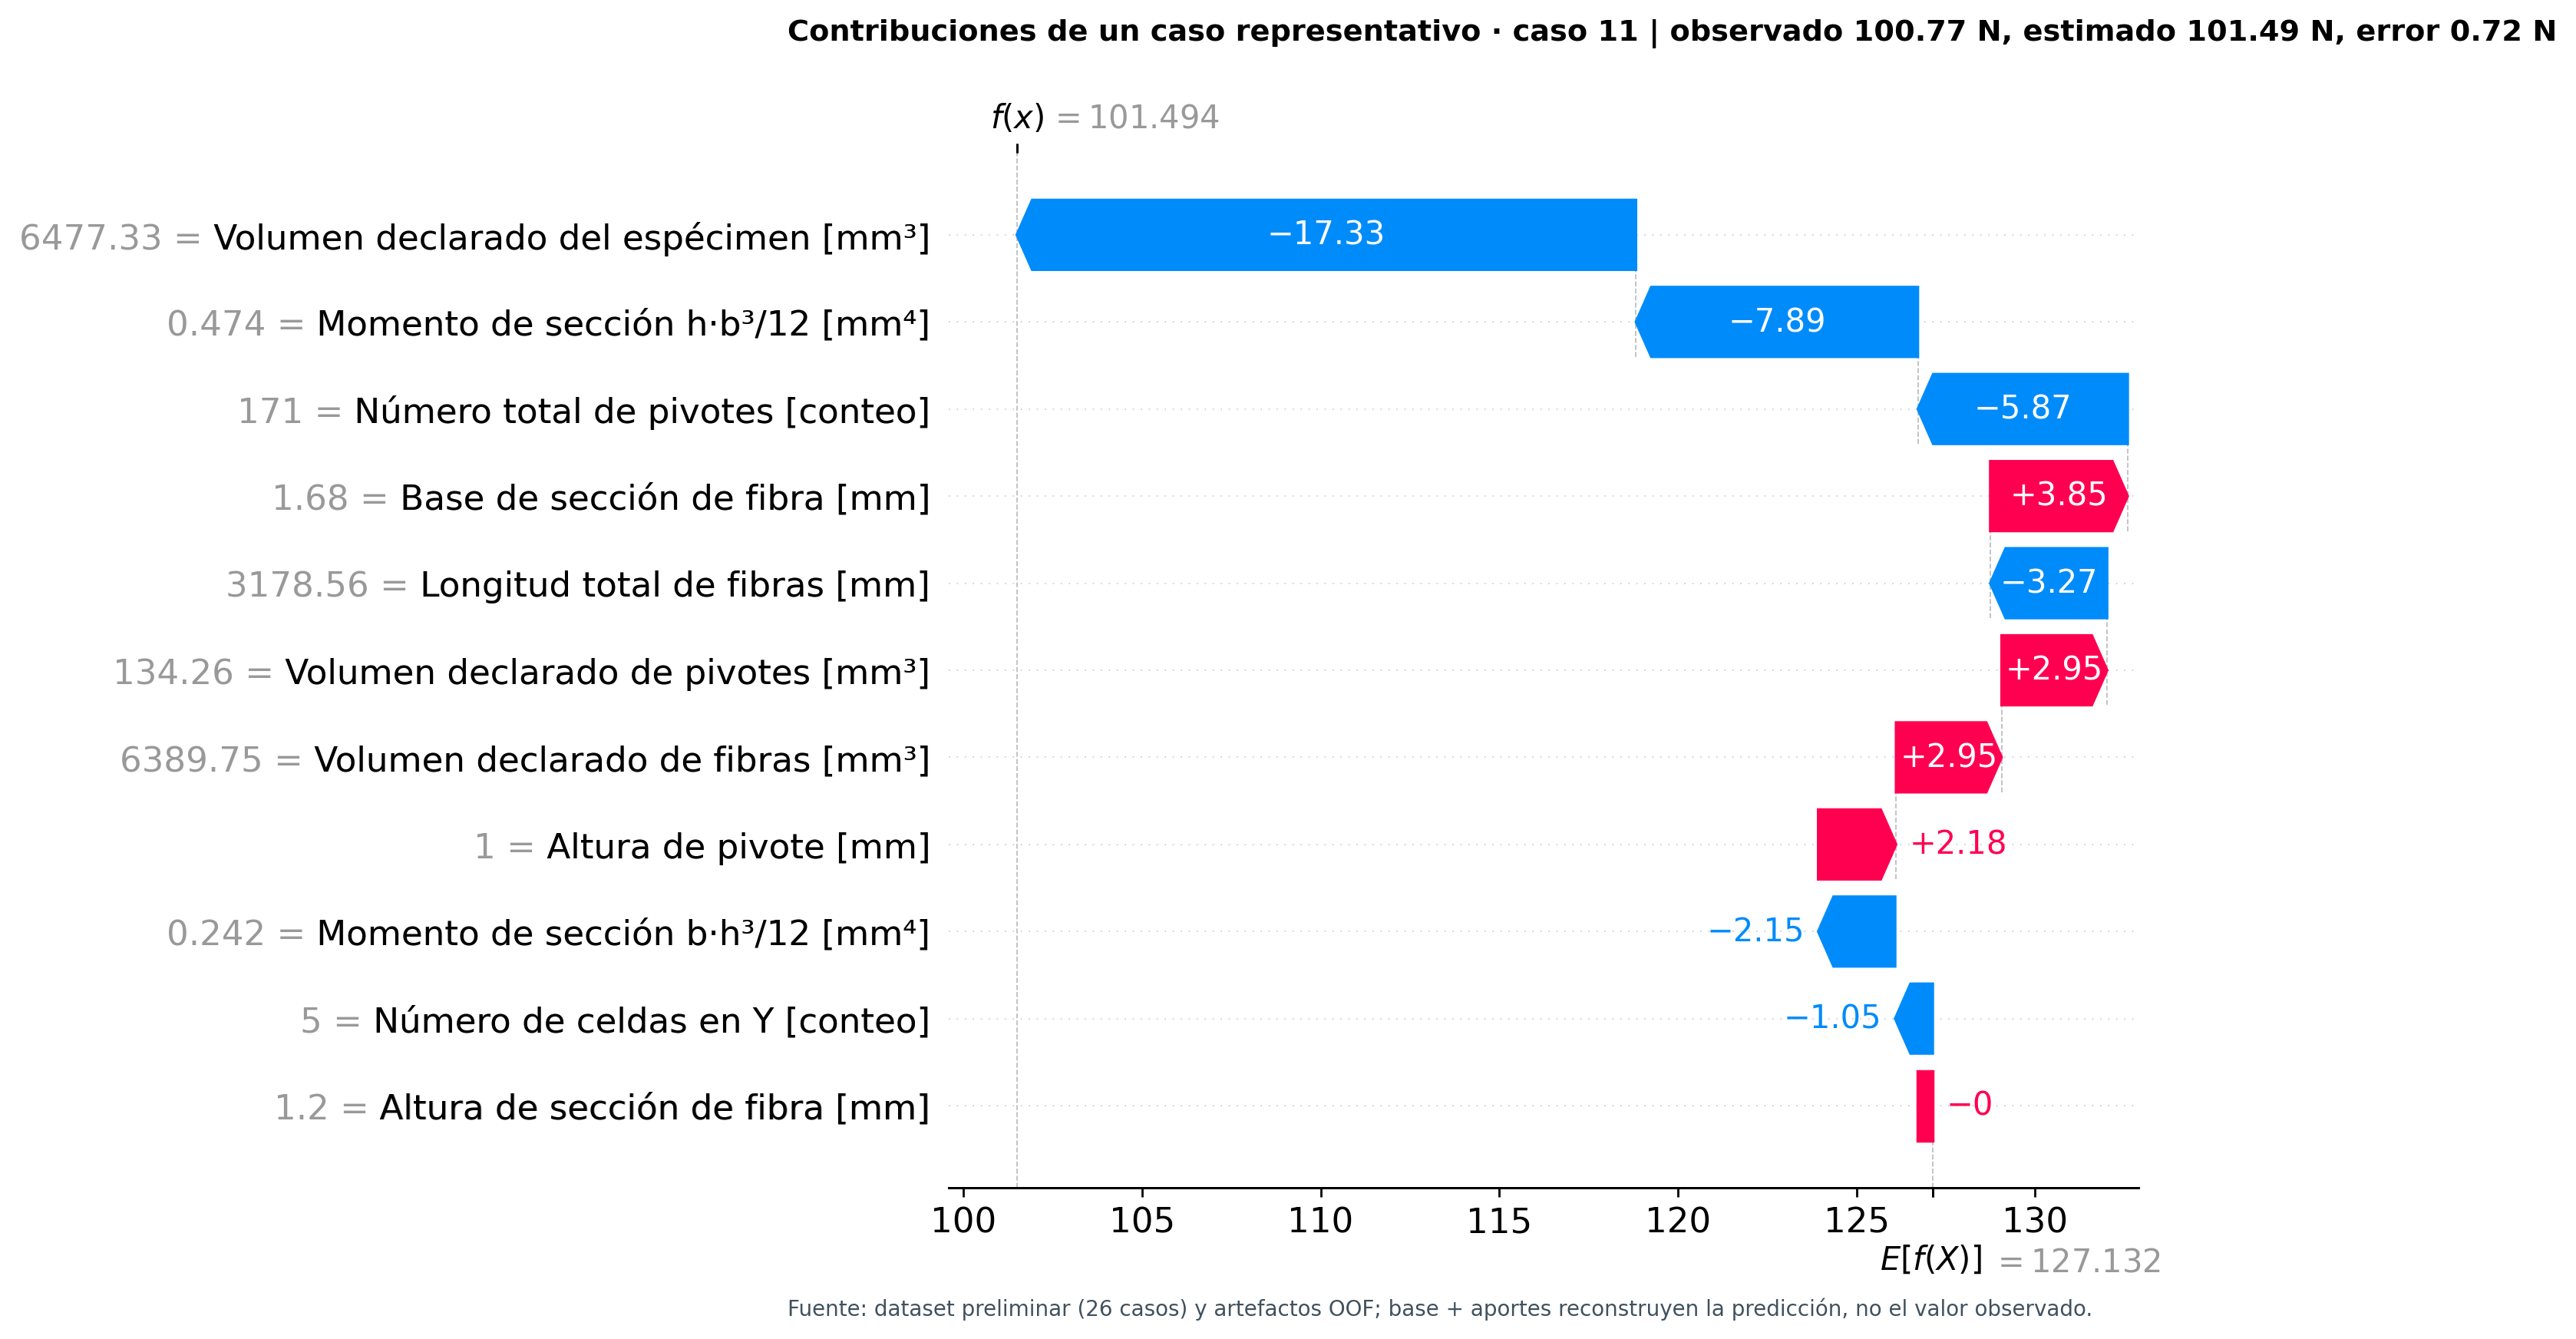

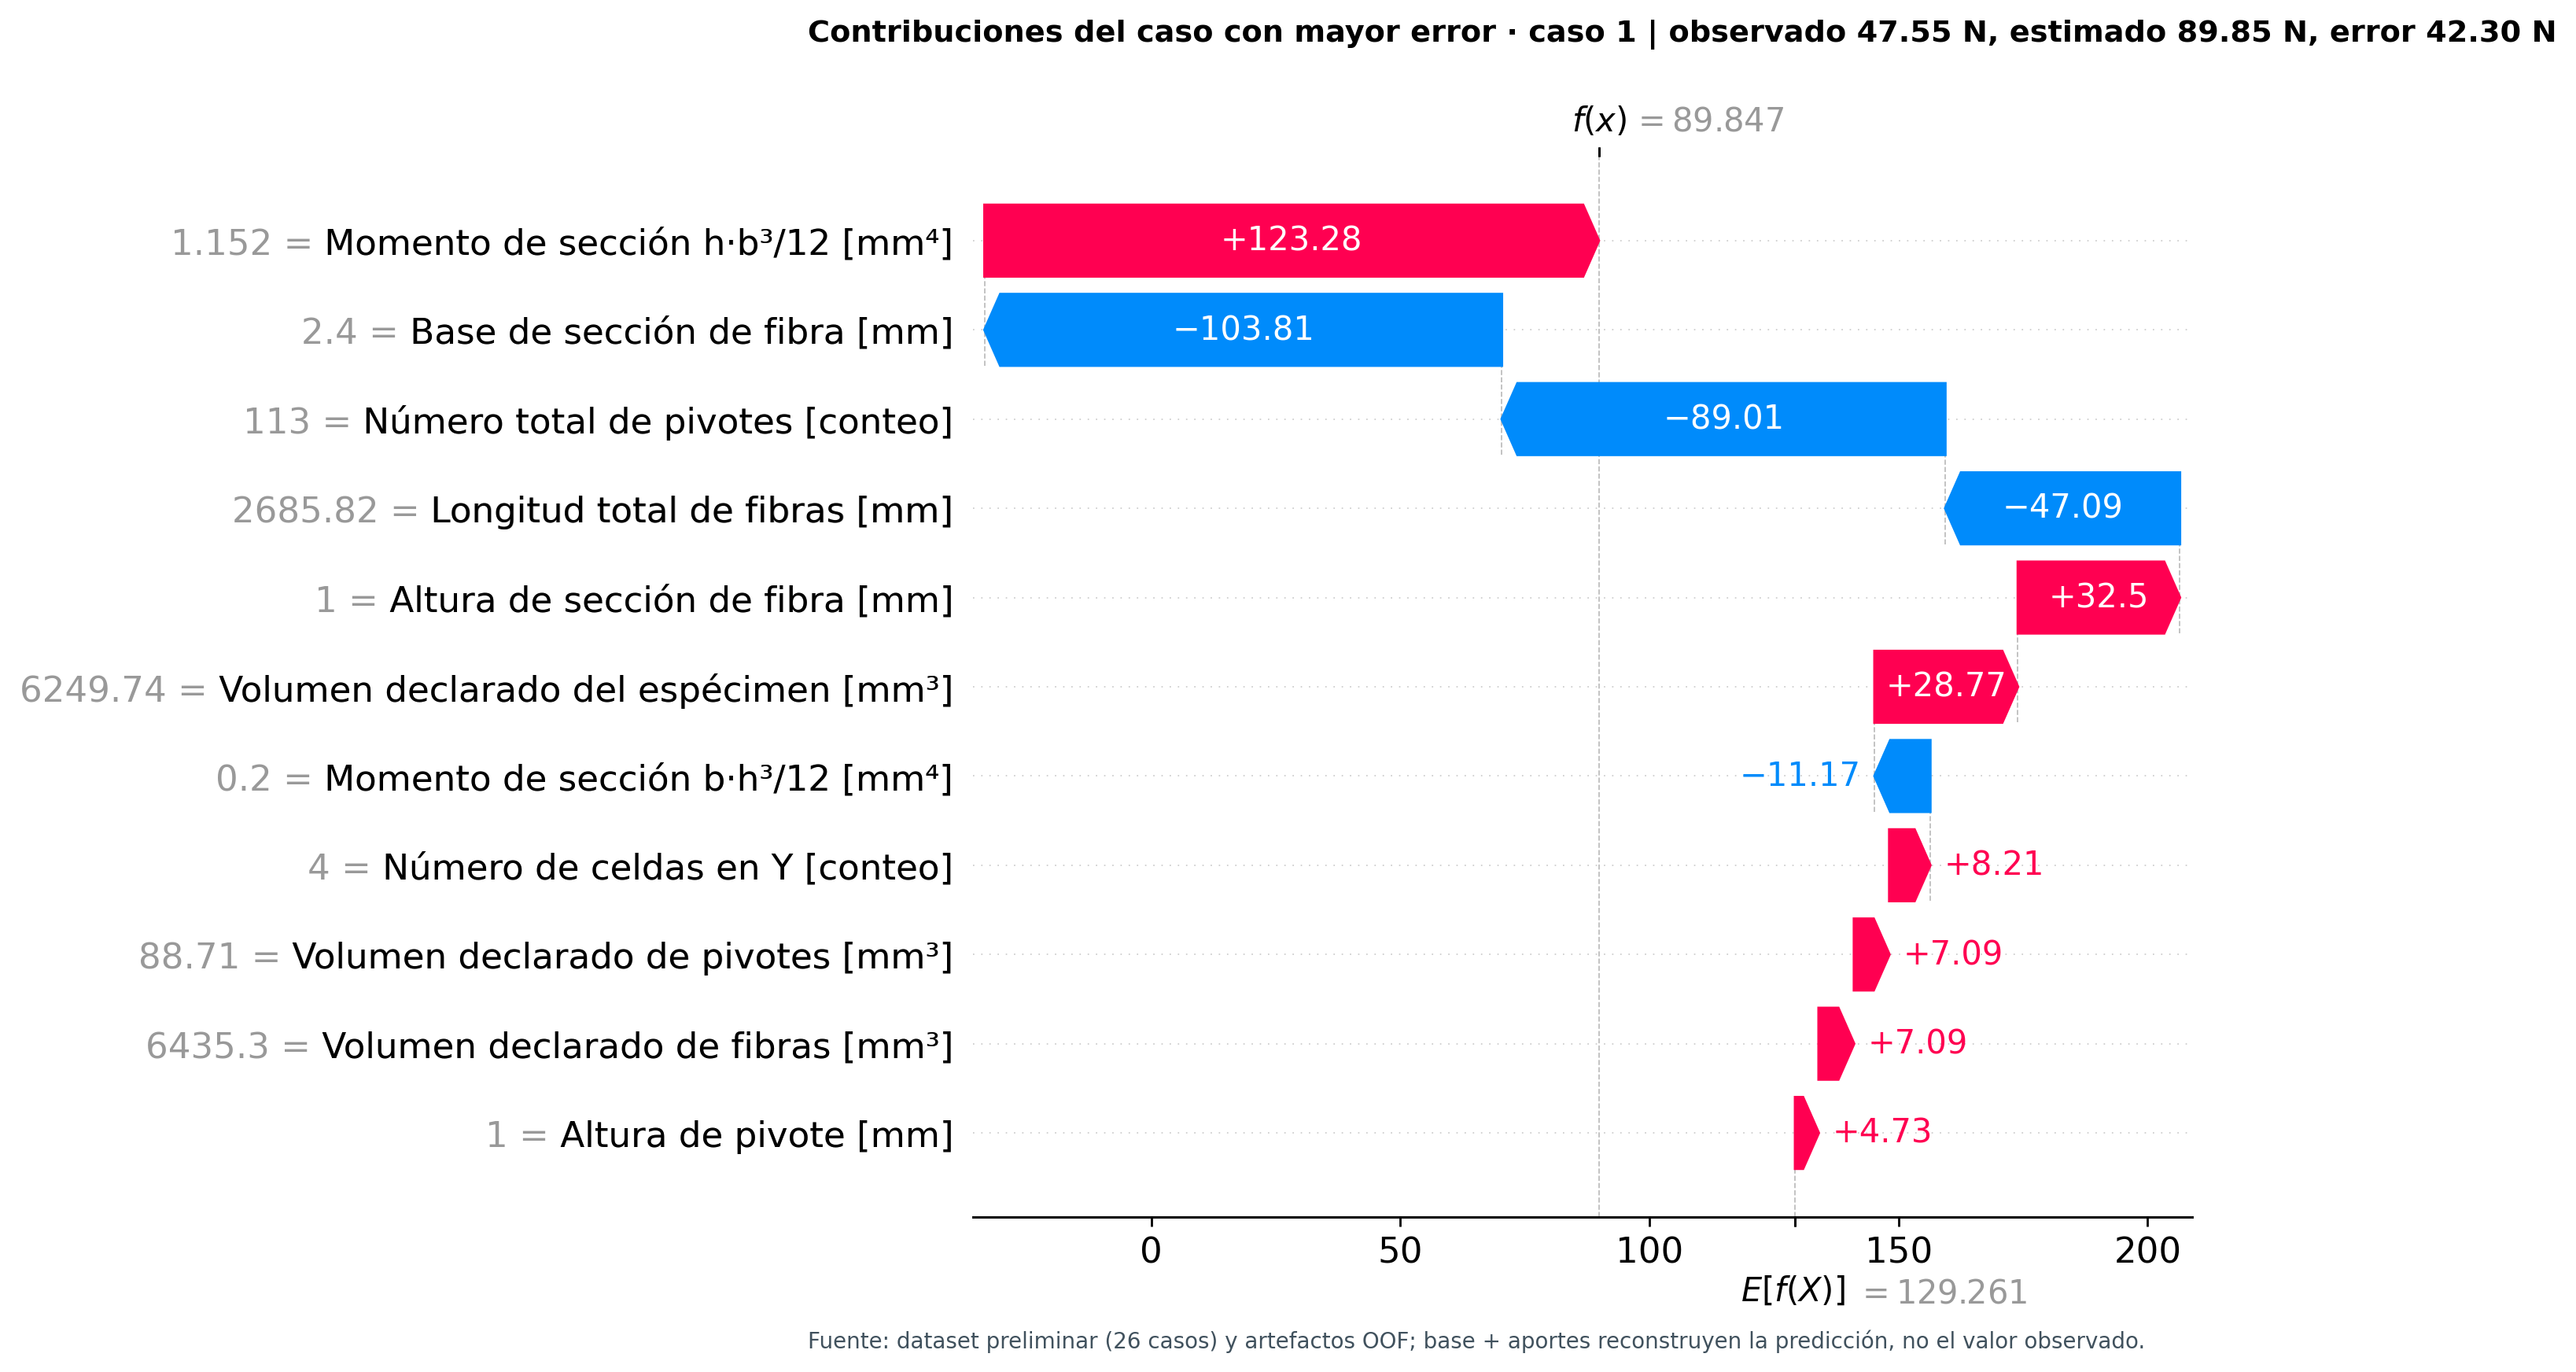

In [13]:
local = pred[pred.protocolo.eq("configuracion") & pred.experimento.eq("E3")].set_index("Case_n")
med_case = int((local.observado_N - local.observado_N.median()).abs().idxmin())
worst_case = int(local.error_absoluto_N.idxmax())
high_case = int(local.observado_N.idxmax())
low_case = int(local.observado_N.nsmallest(2).index[-1])
assert [med_case, worst_case, high_case, low_case] == [11, 1, 22, 5]
motivos = {11:"cerca de mediana", 1:"error máximo", 22:"carga alta", 5:"carga baja"}
rows = []
for case in [11, 1, 22, 5]:
    p = local.loc[case]
    v = shap_oof[shap_oof.protocolo.eq("configuracion") & shap_oof.experimento.eq("E3") &
                 shap_oof.Case_n.eq(case)].copy()
    pos = v.nlargest(3, "shap_N")
    neg = v.nsmallest(3, "shap_N")
    fmt = lambda t: "; ".join(f"{LABELS.get(r.feature,r.feature).split(' [')[0]} {r.shap_N:+.2f} N" for r in t.itertuples())
    assert np.isclose(v.base_N.iloc[0] + v.shap_N.sum(), p.predicho_N, atol=1e-6)
    rows.append({"Caso":case, "Motivo":motivos[case], "Observado [N]":p.observado_N,
                 "Estimado [N]":p.predicho_N, "Error estimado − observado [N]":p.predicho_N-p.observado_N,
                 "Base SHAP [N]":v.base_N.iloc[0], "Aumentan":fmt(pos), "Reducen":fmt(neg)})
display(pd.DataFrame(rows).round(2))
figura(7)
figura(8)

<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación de los resultados.</strong></p>
<p>En el caso 11, el modelo estima 101,49 N frente a 100,77 N observados. Desde un valor base de 127,13 N, el volumen declarado del espécimen (−17,33 N) y el momento geométrico h·b³/12 (−7,89 N) son las principales contribuciones descendentes. El error final es de +0,72 N, pero ese acierto individual no demuestra que la relación sea estable en otros diseños.</p>
<p>El caso 1 concentra el mayor error de E3: 89,85 N estimados frente a 47,55 N observados. El momento h·b³/12 aporta +123,28 N, mientras la base de fibra y el número de pivotes aportan −103,81 y −89,01 N. Estas contribuciones grandes y contrapuestas, junto con otras de menor magnitud, se cancelan parcialmente; el residual de +42,30 N advierte que la explicación aditiva del modelo no equivale a una explicación acertada del ensayo.</p>
<p>En el caso 22, de carga alta, pivotes (+58,25 N) y longitud de fibras (+43,25 N) elevan la estimación hasta 204,36 N, frente a 215,52 N observados. En el caso 5, celdas Y (+186,53 N) y pivotes (−240,11 N) muestran otra compensación intensa; se estiman 70,50 N frente a 59,68 N. La colinealidad impide asignar estas magnitudes a mecanismos físicos independientes.</p>
</div>

### 1.7 Contraste de importancia mediante permutación, correlación y ablación

La importancia por permutación se expresa como el aumento del MAE cuando se altera una fuente de entrada: MAE permutado menos MAE original. Se realizaron 12 repeticiones para Ridge con B ajustado. Dado que muchas particiones externas contienen un solo caso, la perturbación se evalúa sobre los 26 casos con sus respectivos modelos externos; los descriptores derivados se recalculan después de alterar sus fuentes. Esta operación puede formar combinaciones geométricas no observadas y no representa una intervención experimental.

,Variable o grupo,Aumento medio de MAE [N],Desv. entre repeticiones [N],Repeticiones
6,Número total de pivotes [conteo],100.737,20.799,12
9,Número de celdas en Y [conteo],60.512,13.388,12
2,Longitud total de fibras [mm],34.111,7.117,12
8,Volumen declarado del espécimen [mm³],20.039,3.387,12
0,Base de sección de fibra [mm],7.093,2.251,12
11,Volúmenes de fibras y pivotes [grupo],7.066,1.731,12
10,Sección de fibra: altura y base [grupo],3.395,1.753,12
1,Altura de sección de fibra [mm],3.221,1.971,12
7,Volumen declarado de pivotes [mm³],2.466,1.153,12
3,Volumen declarado de fibras [mm³],2.348,1.084,12


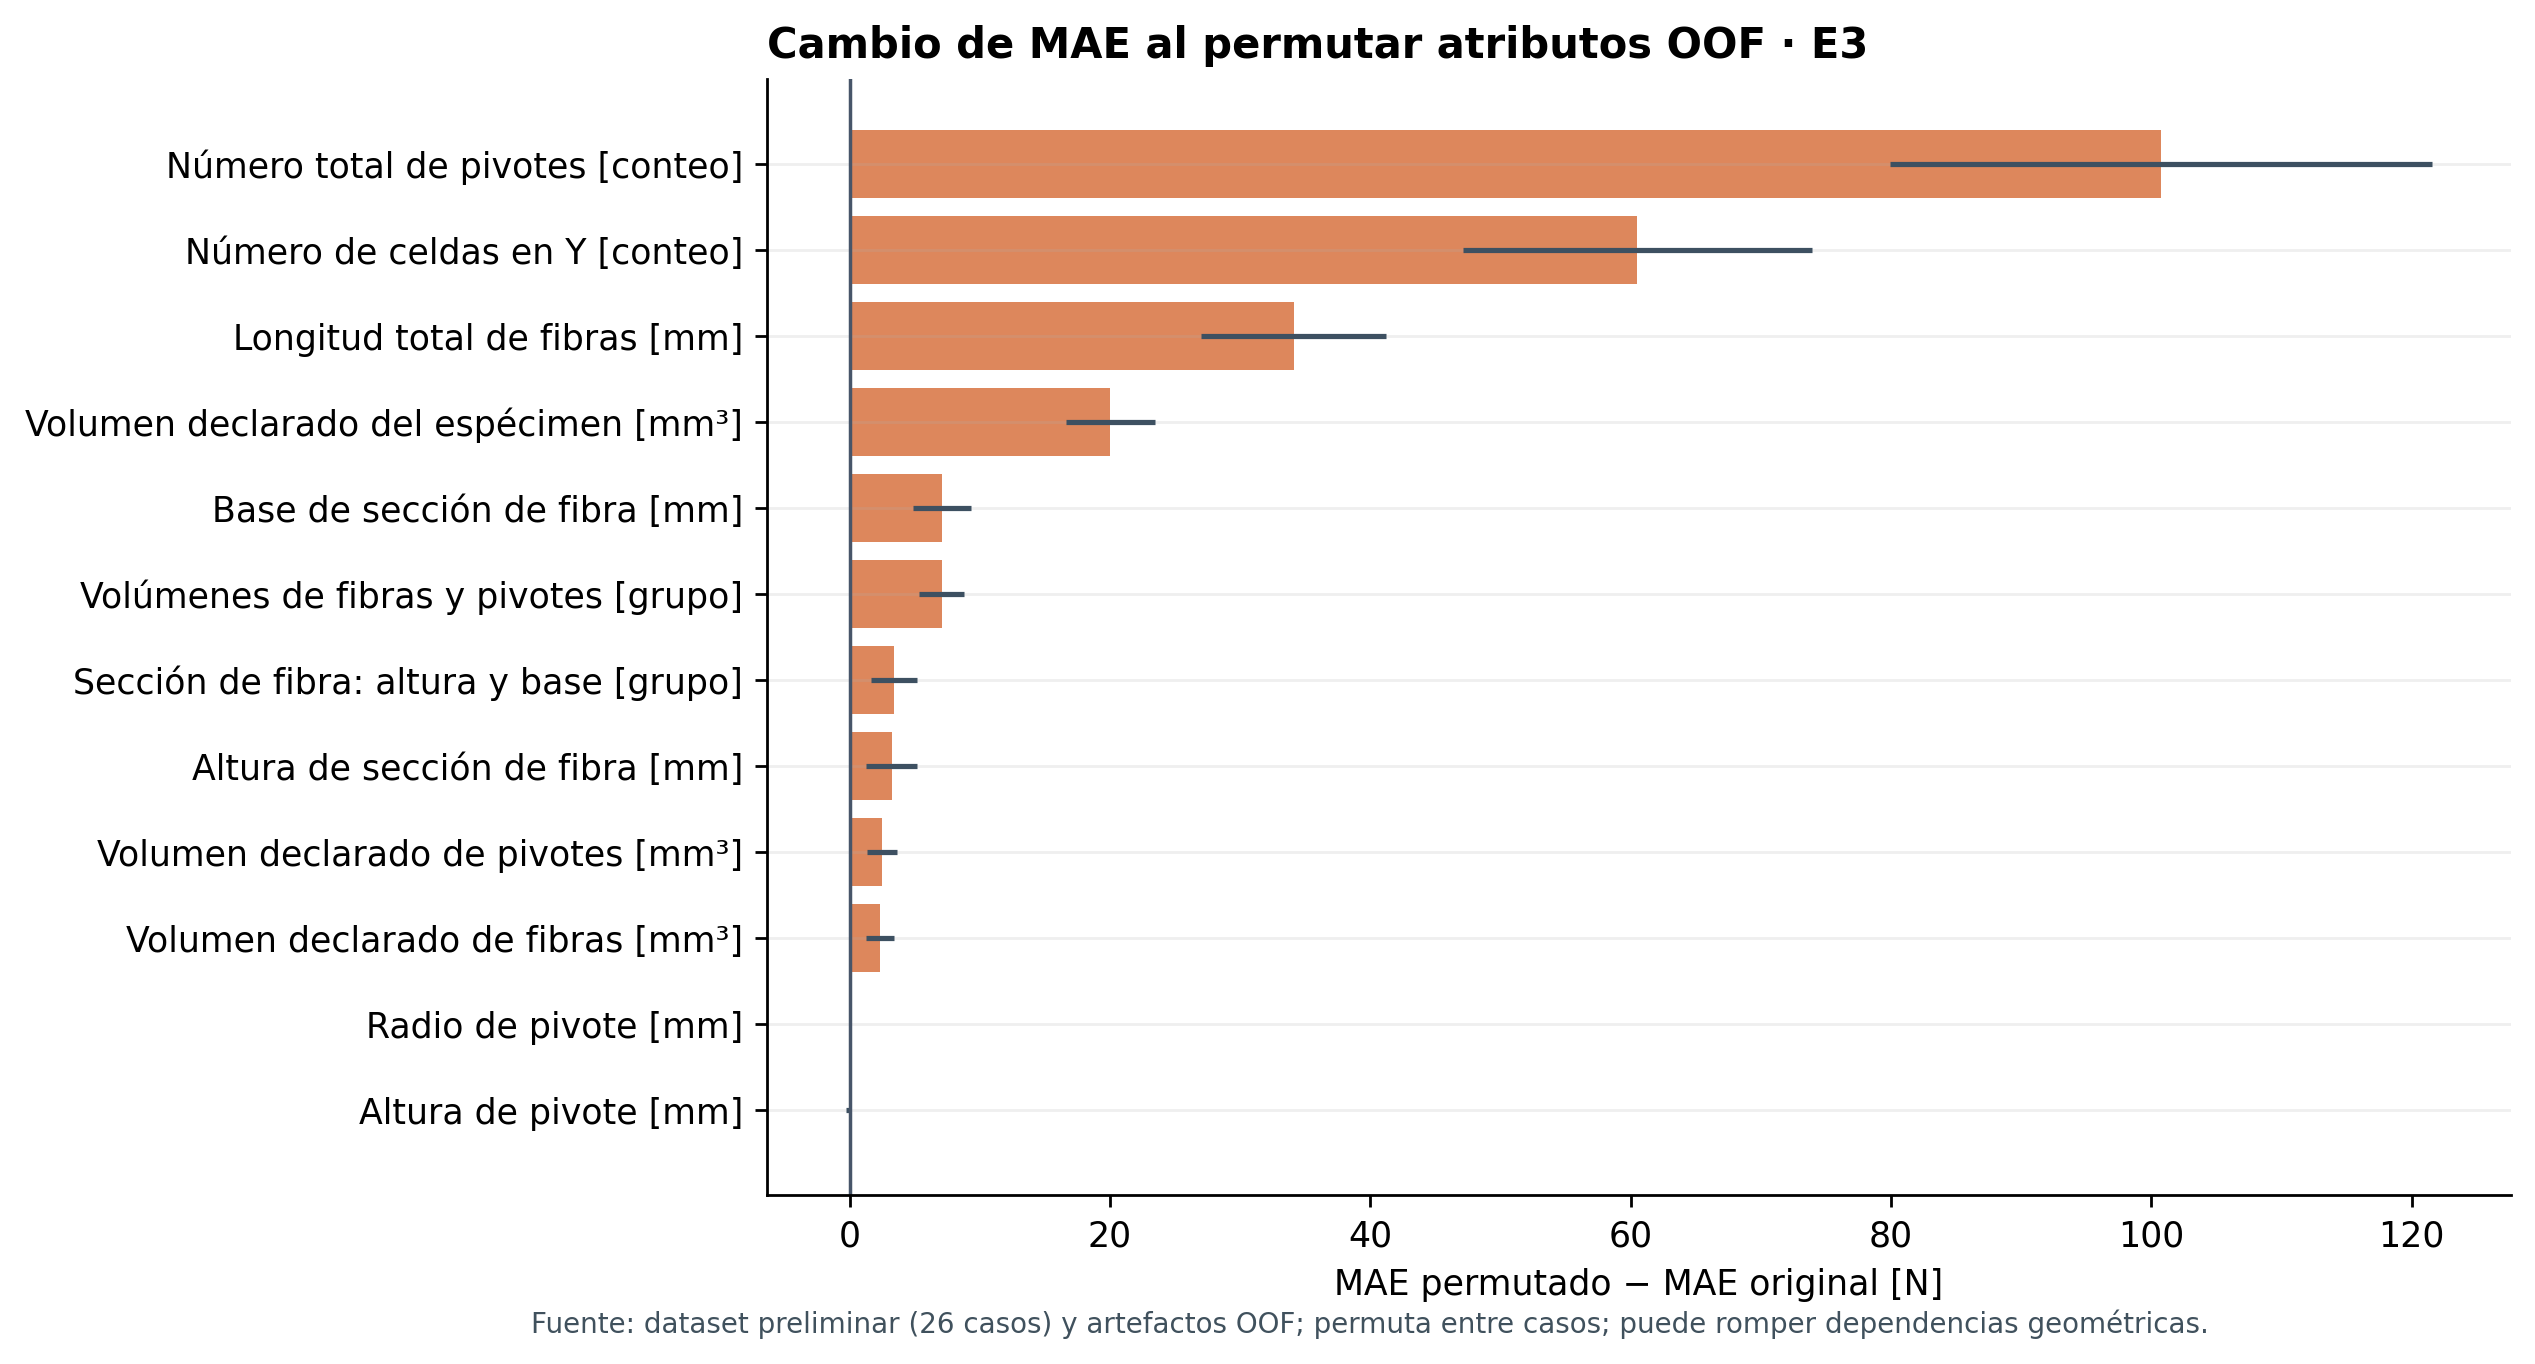

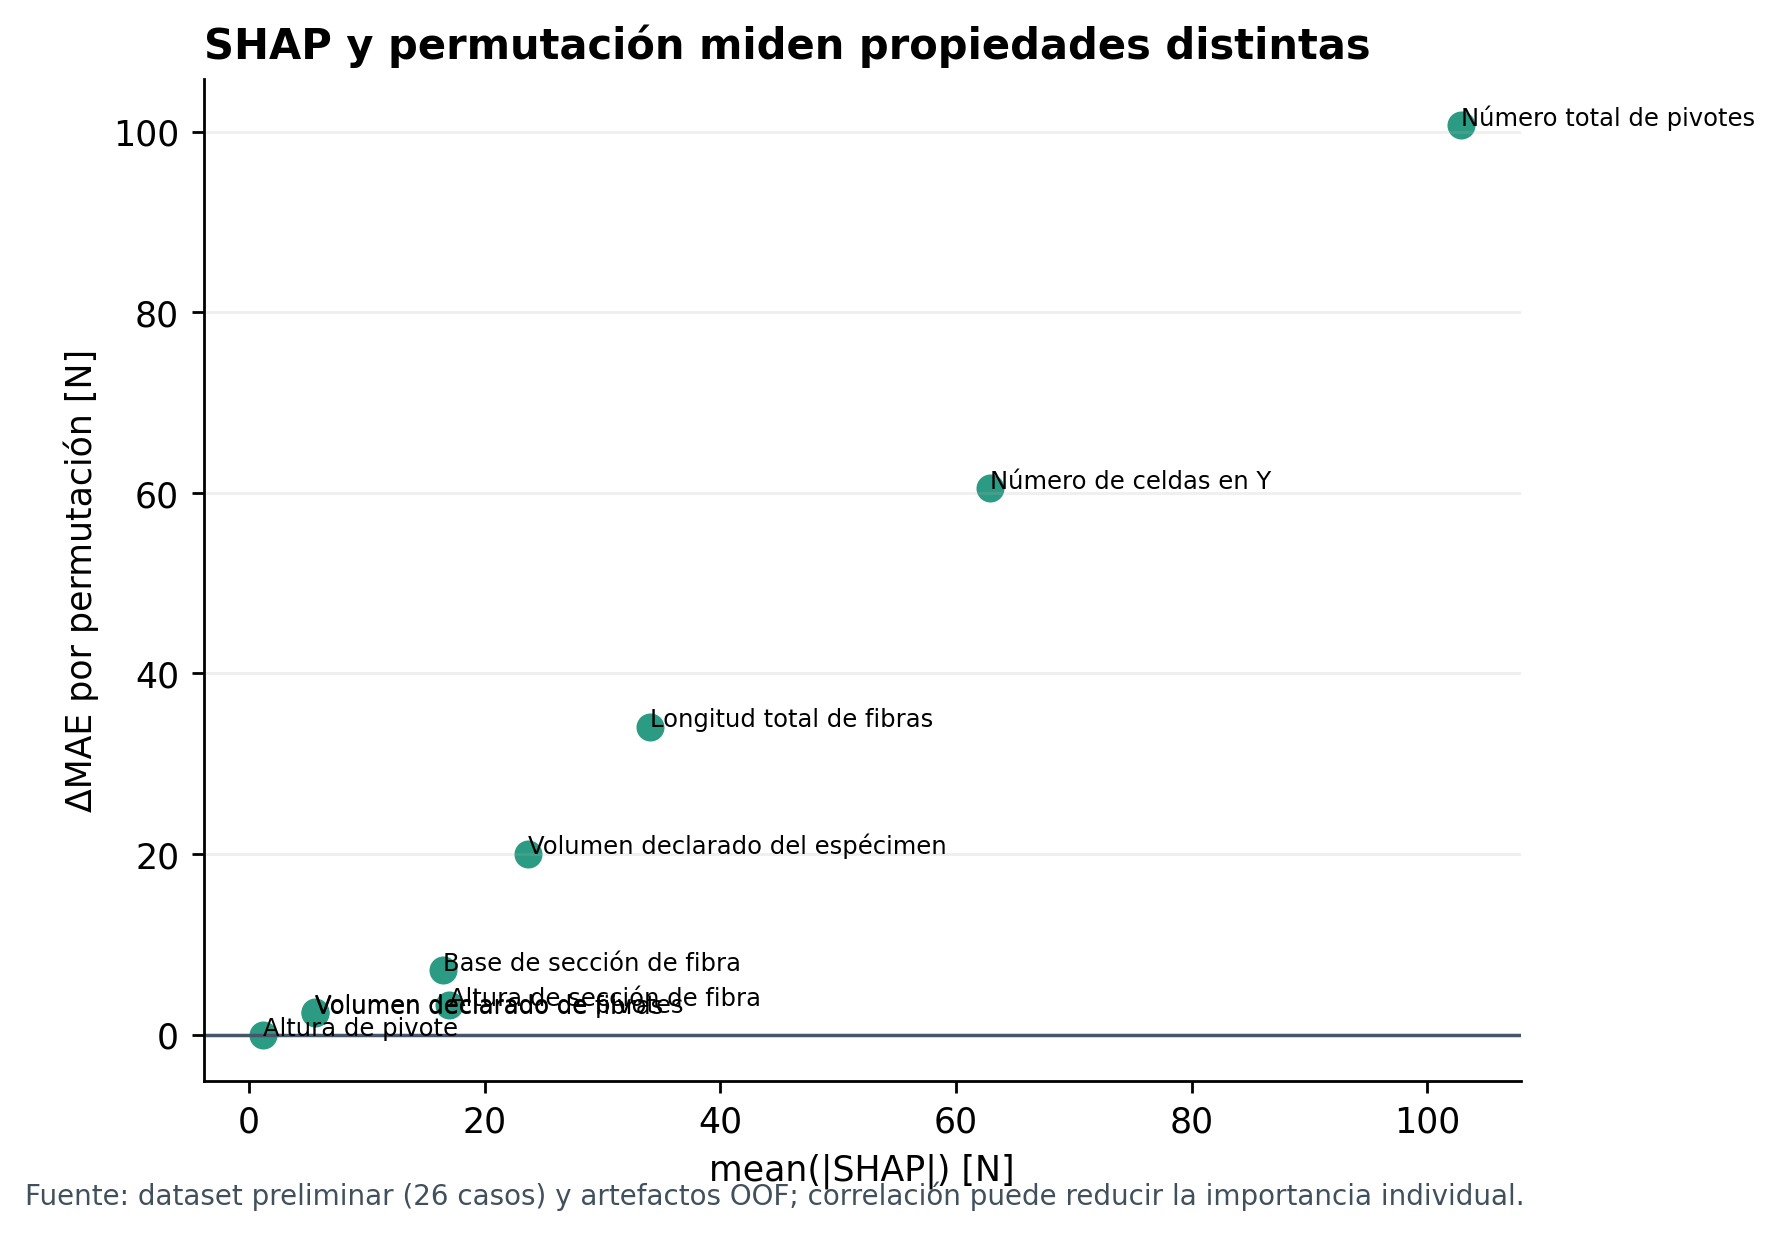

In [14]:
perm = tabla("permutacion")
p = perm[perm.protocolo.eq("configuracion") & perm.experimento.eq("E3")].copy()
p["Variable o grupo"] = p.feature_or_group.map(lambda f: LABELS.get(f, f))
display(p.sort_values("importancia_media_N", ascending=False)
        [["Variable o grupo", "importancia_media_N", "importancia_sd_N", "n_repeticiones"]]
        .rename(columns={"importancia_media_N": "Aumento medio de MAE [N]",
                         "importancia_sd_N": "Desv. entre repeticiones [N]",
                         "n_repeticiones": "Repeticiones"}).round(3))
figura(12)
figura(13)

<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación de los resultados.</strong></p>
<p>La permutación del número de pivotes aumenta el MAE de E3 en 100,74 ± 20,80 N; la del número de celdas Y, en 60,51 ± 13,39 N; y la de la longitud de fibras, en 34,11 ± 7,12 N. El orden concuerda con las variables de mayor magnitud SHAP. La concordancia indica dependencia predictiva del modelo bajo esta perturbación, pero no permite separar el efecto de variables que cambian conjuntamente en los diseños disponibles.</p>
<p>La altura de pivote tiene una importancia por permutación cercana a cero (−0,05 ± 0,19 N). Esta estimación se limita a los diseños y al modelo evaluados: bajo colinealidad, una baja importancia individual tampoco demuestra irrelevancia física.</p>
</div>

,Variable 1,Variable 2,Correlación de Pearson,Correlación de Spearman
36,Volumen declarado de fibras [mm³],Volumen declarado de pivotes [mm³],-1.0000,-1.0000
29,Longitud total de fibras [mm],Número total de pivotes [conteo],0.9997,1.0000
2,Número de celdas en Y [conteo],Longitud total de fibras [mm],0.9995,1.0000
5,Número de celdas en Y [conteo],Número total de pivotes [conteo],0.9985,1.0000
26,Base de sección de fibra [mm],Momento de sección h·b³/12 [mm⁴],0.9735,0.9818
17,Altura de sección de fibra [mm],Momento de sección b·h³/12 [mm⁴],0.9317,0.9440
7,Número de celdas en Y [conteo],Volumen declarado del espécimen [mm³],0.9195,0.9043
45,Número total de pivotes [conteo],Volumen declarado de pivotes [mm³],0.9122,0.9488


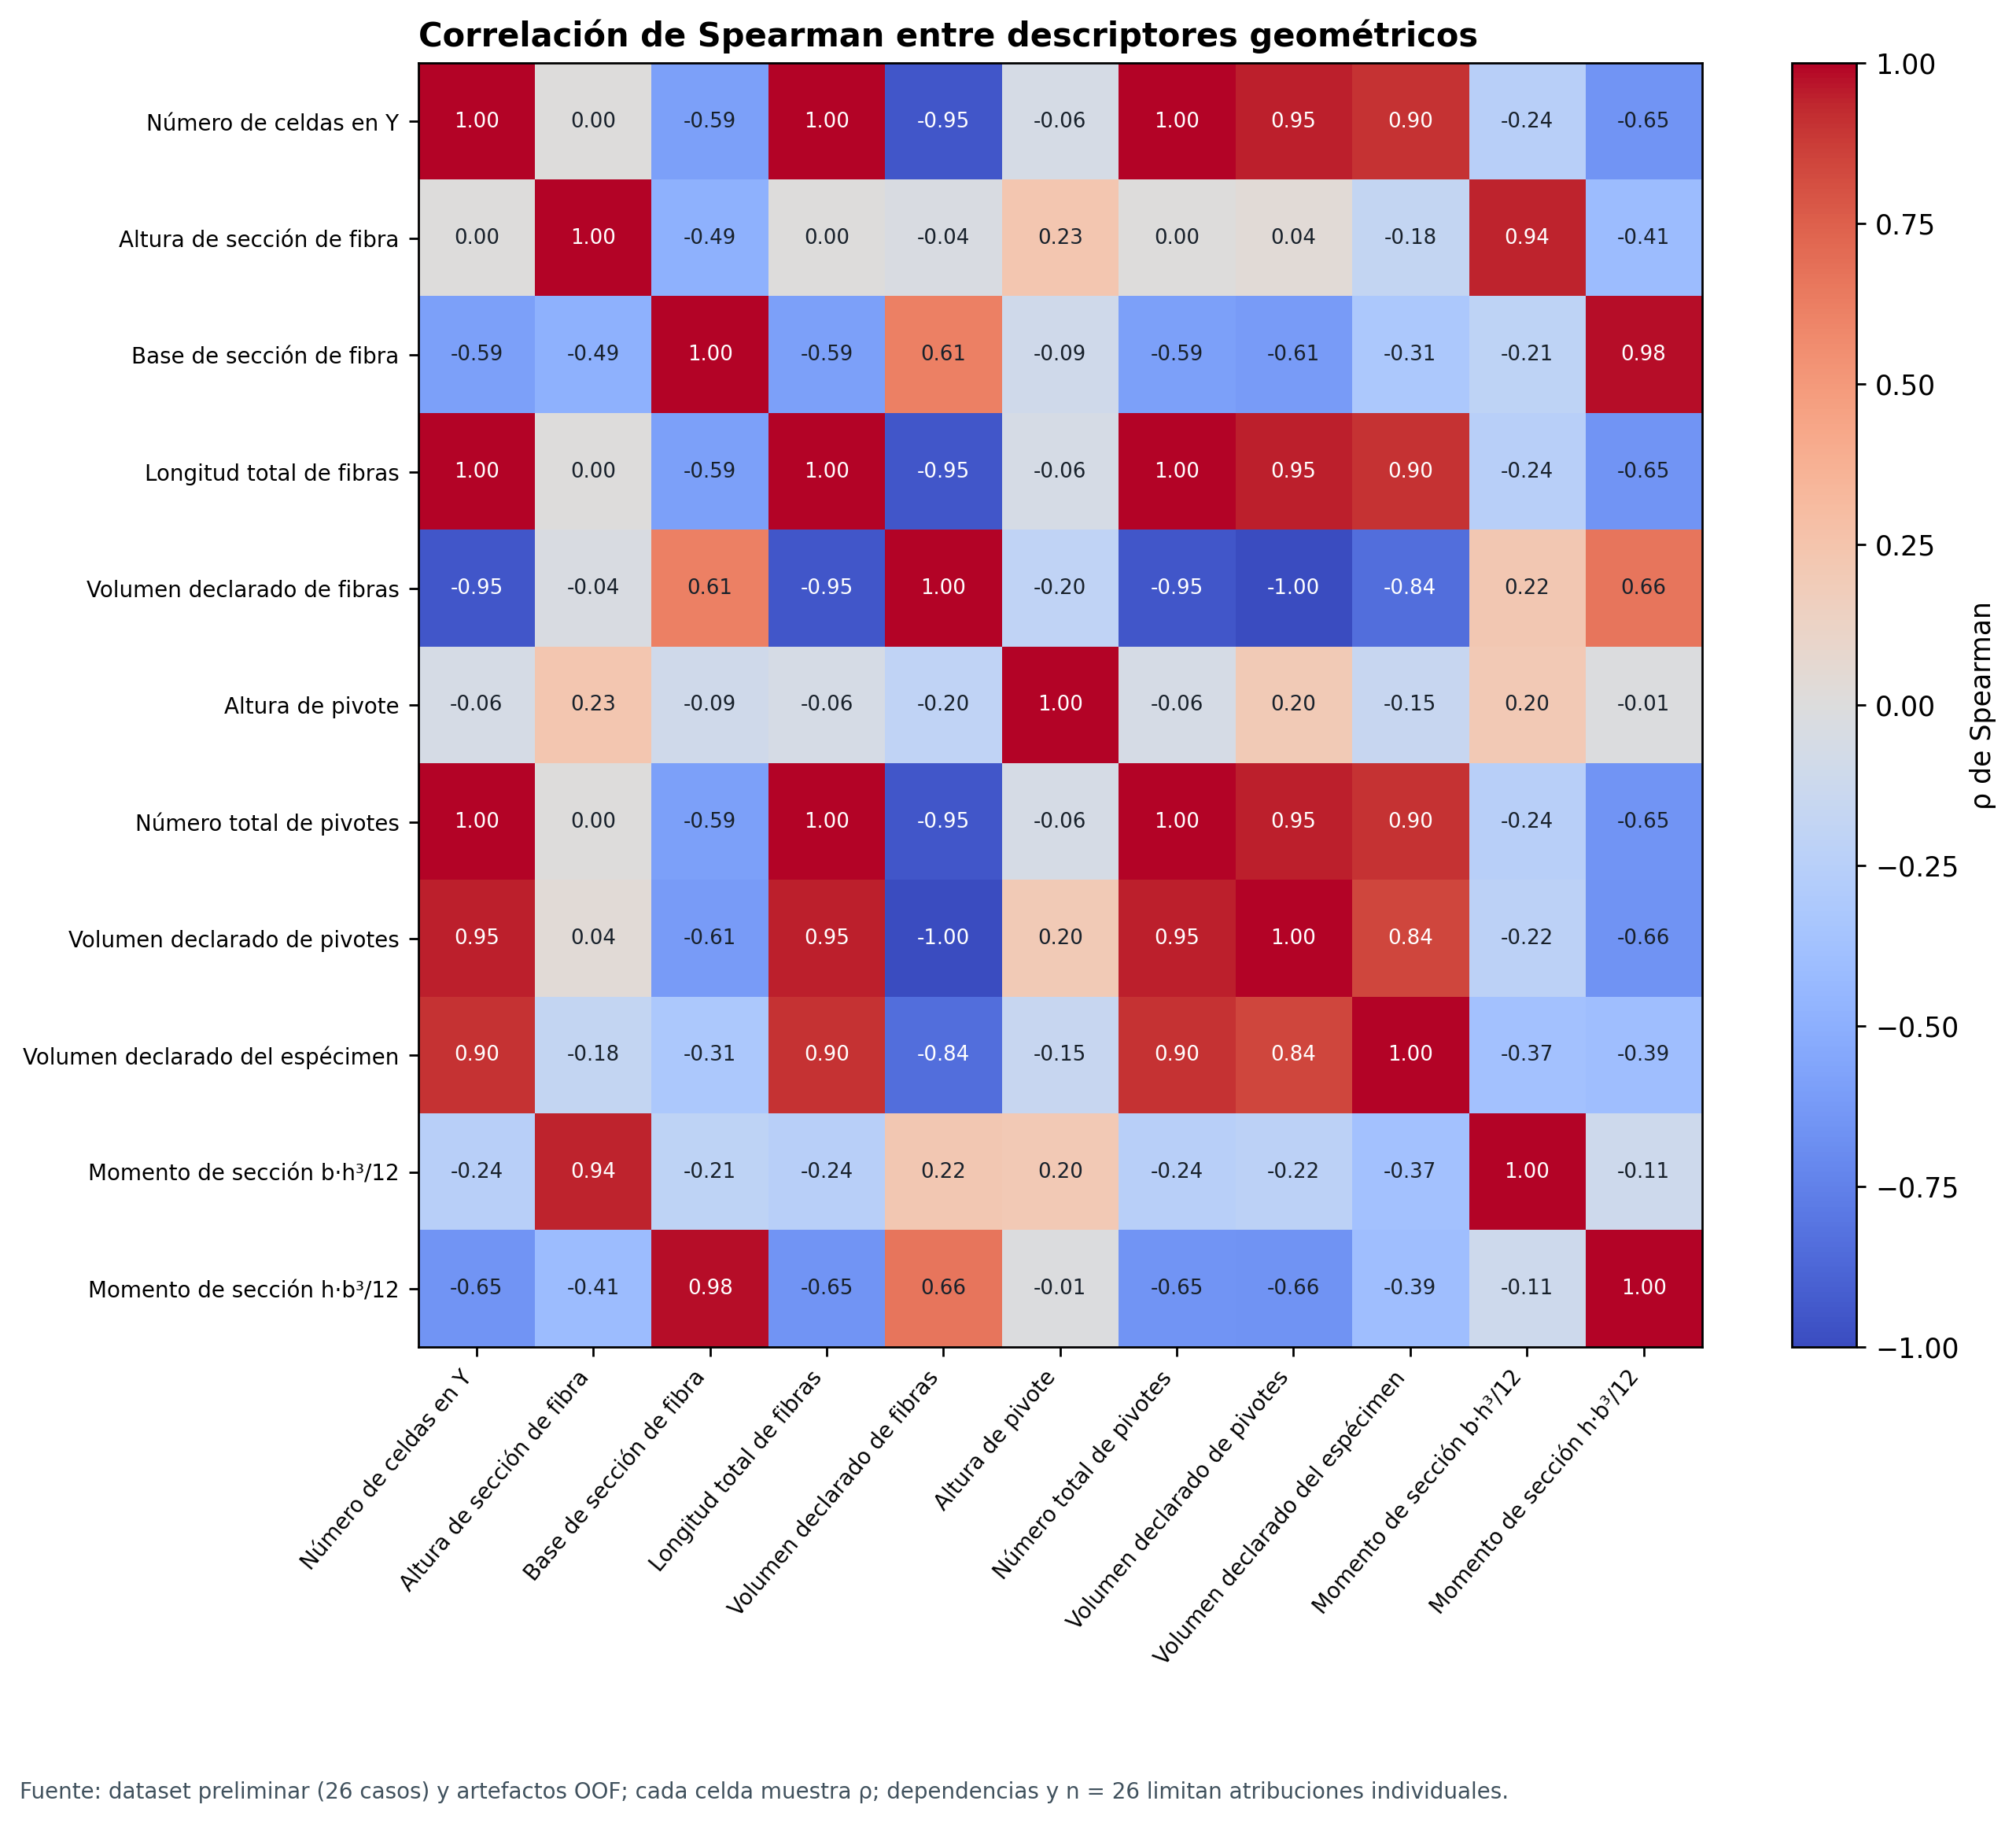

In [15]:
correlaciones = tabla("correlaciones")
top_corr = correlaciones.assign(abs_r=correlaciones.pearson_r.abs()).nlargest(8, "abs_r").copy()
top_corr["Variable 1"] = top_corr.feature_1.map(lambda f: LABELS.get(f, f))
top_corr["Variable 2"] = top_corr.feature_2.map(lambda f: LABELS.get(f, f))
display(top_corr[["Variable 1", "Variable 2", "pearson_r", "spearman_rho"]]
        .rename(columns={"pearson_r": "Correlación de Pearson",
                         "spearman_rho": "Correlación de Spearman"}).round(4))
figura(14)

<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación de los resultados.</strong></p>
<p>Los volúmenes declarados de fibras y pivotes muestran correlación de Pearson igual a −1,0000 en la tabla analizada; longitud de fibras y número de pivotes alcanzan 0,9997, y número de celdas Y y longitud de fibras, 0,9995. Los momentos comparten base y altura con los predictores originales. Estas dependencias dificultan atribuir a una variable aislada el desempeño que corresponde a un conjunto de descriptores relacionados.</p>
<p>La dependencia lineal exacta entre los dos volúmenes hace que un factor de inflación de varianza individual no sea finito o estable. La correlación y la identidad algebraica describen aquí el problema con mayor fidelidad que un VIF numérico.</p>
</div>

,Variables,MAE [N],MSE [N²],RMSE [N]
3,B · con momentos,10.981,207.307,14.398
4,A · sin momentos,9.707,152.049,12.331


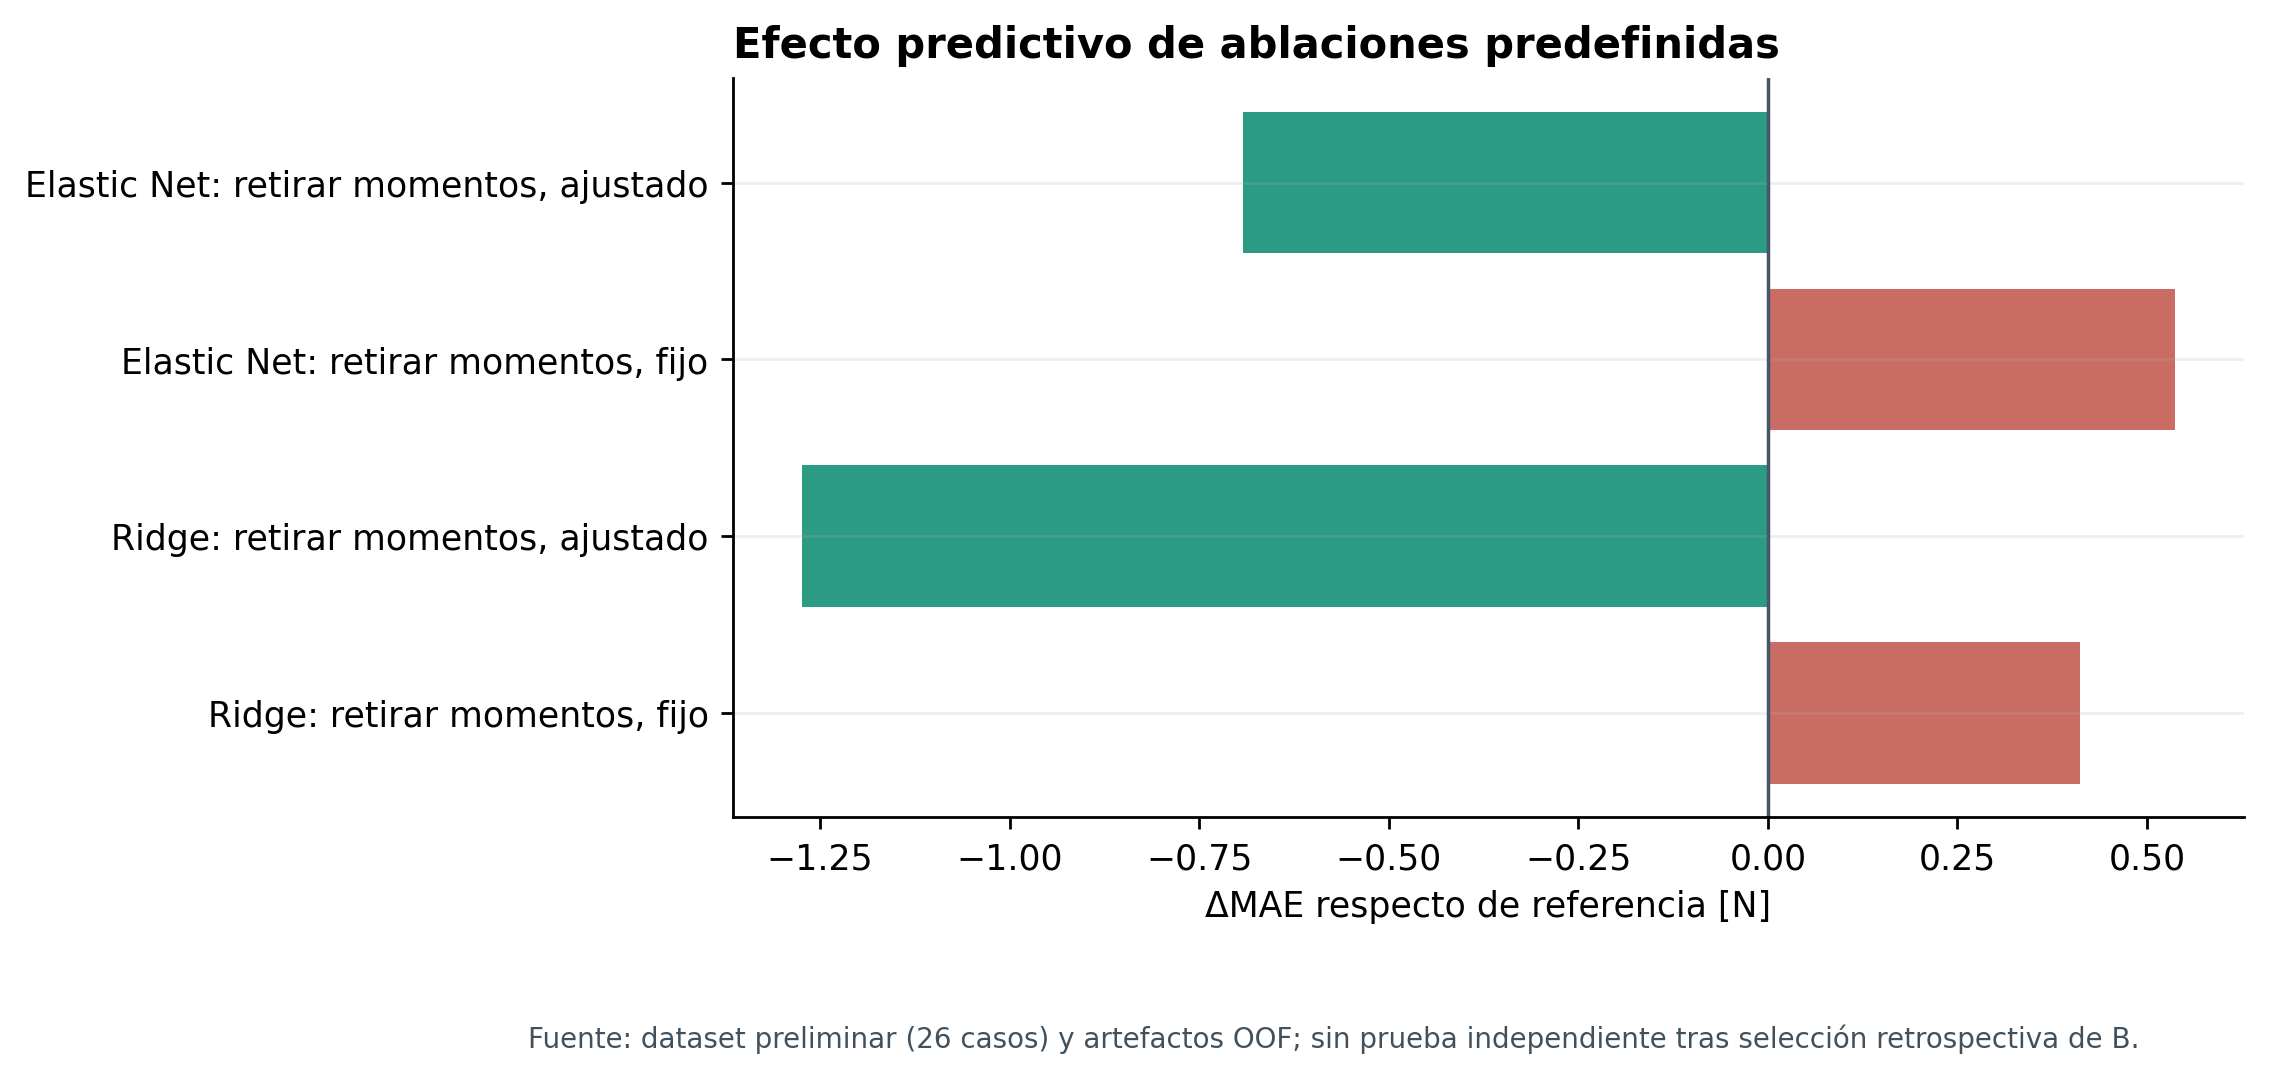

In [16]:
comparacion_ablacion = metricas[metricas.protocolo.eq("configuracion") &
                             metricas.experimento.isin(["E3", "E4"])].copy()
comparacion_ablacion["Variables"] = comparacion_ablacion.experimento.map({
    "E3": "B · con momentos", "E4": "A · sin momentos"})
comparacion_ablacion["MSE_N2"] = comparacion_ablacion.RMSE_N ** 2
display(comparacion_ablacion[["Variables", "MAE_N", "MSE_N2", "RMSE_N"]]
        .rename(columns={"MAE_N": "MAE [N]", "MSE_N2": "MSE [N²]",
                         "RMSE_N": "RMSE [N]"}).round(3))
figura(15)

<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación.</strong> En el contraste con ajuste equivalente, retirar ambos momentos de B reduce el MAE en 1,274 N, el MSE en 55,258 N² y el RMSE en 2,067 N. La ablación mide el cambio de desempeño tras volver a entrenar; por ello complementa, pero no sustituye, la atribución SHAP del modelo B ya ajustado.</p>
</div>

Modelo,E3,E4,S3
Familia de variables,,,
arquitectura,85.25,82.10,88.13
pivotes,5.89,6.16,4.90
seccion_fibra,9.38,3.49,9.62
volumen_global_y_fibras,28.58,21.81,31.75


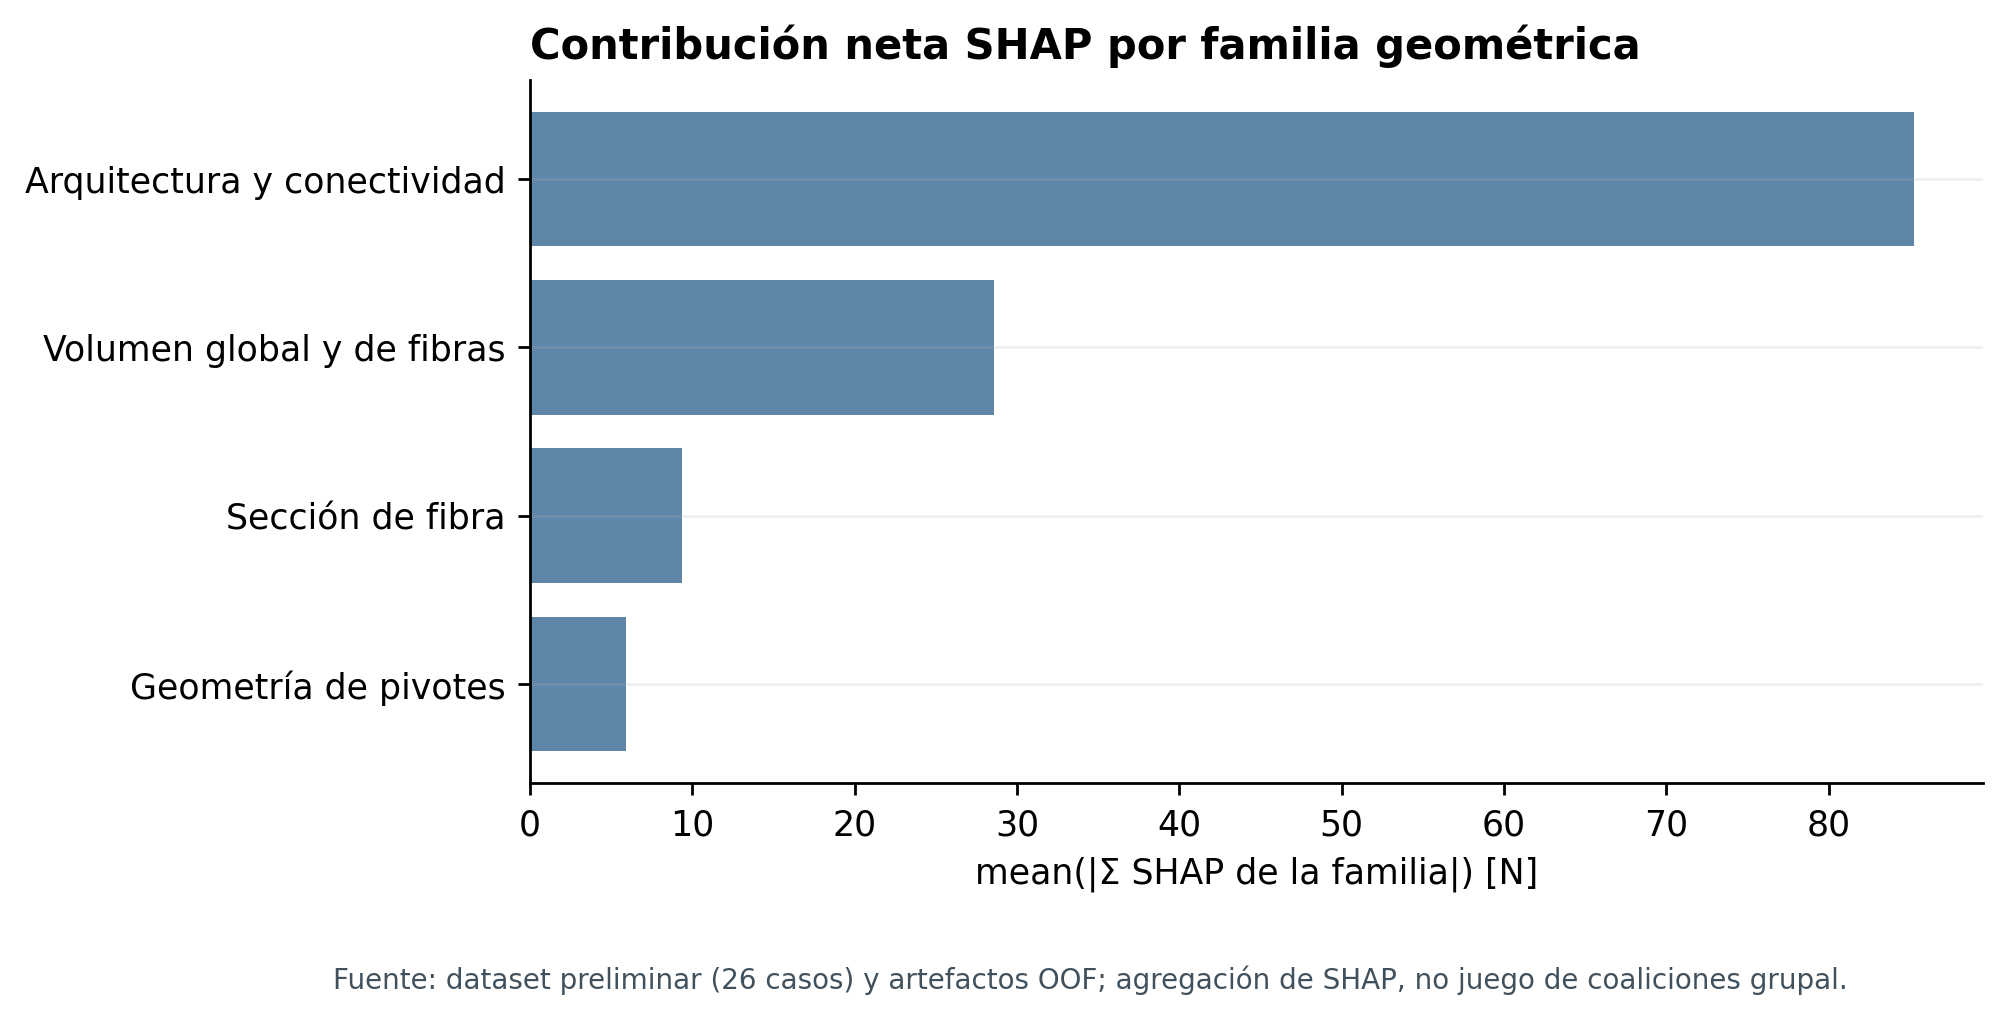

In [17]:
familias_shap = tabla("shap_familias")
familias_resumen = (familias_shap[familias_shap.protocolo.eq("configuracion") &
                                familias_shap.experimento.isin(["E3", "S3", "E4"])]
                    .groupby(["experimento", "familia_geometrica"], as_index=False)
                    .mean_abs_sum_shap_N.first())
display(familias_resumen.pivot(index="familia_geometrica", columns="experimento",
                               values="mean_abs_sum_shap_N")
        .rename_axis(index="Familia de variables", columns="Modelo").round(2))
figura(16)

<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación de los resultados.</strong></p>
<p>La suma de contribuciones SHAP con signo dentro de cada familia geométrica, seguida de la media de su valor absoluto entre casos, asigna en E3 85,25 N al bloque de arquitectura y 9,38 N al de sección de fibra. La agregación permite reconocer información compartida y cancelaciones internas, pero es descriptiva: no constituye un cálculo formal de valores de Shapley para grupos de variables.</p>
</div>

#### 1.7.1 Importancia de las variables y desempeño del modelo

Las métricas de error pertenecen al modelo completo; SHAP y permutación describen su dependencia de entradas particulares. La tabla reúne las diez variables originales y las tres derivadas estudiadas. El radio de pivote, constante en la muestra, y la razón logarítmica, evaluada solo en la etapa anterior, se muestran sin atribuciones SHAP para los modelos que no las utilizaron.

In [18]:
geometria = frame[GEOMETRY].copy()
geometria[MOMENTS] = geometry_features(geometria)[MOMENTS]
geometria[LOG_RATIO] = np.log(geometria.Pivot_total_volume) - np.log(geometria.Fiber_total_volume)
rho = geometria.apply(lambda col: col.corr(y, method="spearman") if col.nunique() > 1 else np.nan)
sh_e3 = shap_global[shap_global.protocolo.eq("configuracion") & shap_global.experimento.eq("E3")].set_index("feature")
sh_e4 = shap_global[shap_global.protocolo.eq("configuracion") & shap_global.experimento.eq("E4")].set_index("feature")
sh_s3 = shap_global[shap_global.protocolo.eq("configuracion") & shap_global.experimento.eq("S3")].set_index("feature")
pm = p.set_index("feature_or_group").importancia_media_N
top5_e3 = top5[top5.experimento.eq("E3")].set_index("feature").fraccion_top5
variables = GEOMETRY + MOMENTS + [LOG_RATIO]
rows_cross = []
for f in variables:
    original = f in GEOMETRY
    rows_cross.append({
        "Variable geométrica": LABELS.get(f, "Logaritmo del volumen pivotes/fibras [sin unidad]"),
        "Origen": "Original" if original else "Derivada",
        "Conjunto evaluado": "A y B" if original else "B" if f in MOMENTS else "C anterior",
        "Asociación con carga (ρ)": rho.get(f, np.nan),
        "SHAP Ridge B [N]": sh_e3.mean_abs_shap_N.get(f, np.nan),
        "SHAP Ridge A [N]": sh_e4.mean_abs_shap_N.get(f, np.nan),
        "SHAP Elastic Net B [N]": sh_s3.mean_abs_shap_N.get(f, np.nan),
        "Aumento de MAE al permutar [N]": pm.get(f, np.nan),
        "Proporción top 5 Ridge B": top5_e3.get(f, np.nan),
    })
tabla_variables = pd.DataFrame(rows_cross)
display(tabla_variables.round(3).fillna("—"))



,Variable geométrica,Origen,Conjunto evaluado,Asociación con carga (ρ),SHAP Ridge B [N],SHAP Ridge A [N],SHAP Elastic Net B [N],Aumento de MAE al permutar [N],Proporción top 5 Ridge B
0,Número de celdas en Y [conteo],Original,A y B,0.931,62.908,153.697,23.861,60.512,0.5
1,Altura de sección de fibra [mm],Original,A y B,0.0,16.986,0.498,17.408,3.221,0.542
2,Base de sección de fibra [mm],Original,A y B,-0.552,16.46,3.238,17.447,7.093,0.5
3,Longitud total de fibras [mm],Original,A y B,0.931,34.039,39.2,30.685,34.111,0.708
4,Volumen declarado de fibras [mm³],Original,A y B,-0.828,5.585,6.643,4.911,2.348,0.0
5,Altura de pivote [mm],Original,A y B,-0.148,1.204,1.067,1.245,-0.054,0.0
6,Radio de pivote [mm],Original,A y B,—,—,—,—,0.0,—
7,Número total de pivotes [conteo],Original,A y B,0.931,102.889,196.598,66.309,100.737,0.875
8,Volumen declarado de pivotes [mm³],Original,A y B,0.828,5.585,6.643,4.545,2.466,0.0
9,Volumen declarado del espécimen [mm³],Original,A y B,0.799,23.678,16.106,27.591,20.039,0.792


<div style="background-color:#eaf3f0; padding:15px 19px; border:0; border-radius:8px; margin:12px 0;">
<p><strong>Interpretación de los resultados.</strong></p>
<p>Las variables de arquitectura —número de pivotes, celdas en Y y longitud total de fibras— dominan SHAP y la perturbación por permutación en Ridge con B ajustado. Sin embargo, el modelo Ridge ajustado con A obtiene menor MAE y RMSE que el ajustado con B. La importancia de los descriptores originales, por consiguiente, no demuestra que añadir los momentos mejore la estimación; esa cuestión la resuelve el contraste controlado A/B y su ablación.</p>
<p>Los momentos describen la distribución ideal de área de la sección rectangular, no la rigidez EI medida ni el estado de daño. El radio de pivote constante no aporta variación predictiva en estos ensayos, mientras la razón de volúmenes de C empeoró ligeramente a B en el contraste previo. Las atribuciones y correlaciones sugieren examinar arquitectura y conectividad en ensayos adicionales con diseños que separen estas dimensiones. Solo observaciones nuevas y mediciones mecánicas comparables podrían sostener una hipótesis sobre mecanismos de primera fractura.</p>
</div>

## 2. Matriz de consistencia metodológica

### 2.1 Planteamiento general

| Problema general | Objetivo general | Hipótesis general | Variable dependiente y variables independientes | Indicadores |
|---|---|---|---|---|
| ¿Puede estimarse la carga de primera falla a partir de la geometría previa al ensayo con menor error que una referencia de mediana y con atribuciones interpretables estables? | Diseñar un procedimiento supervisado para estimar la carga de primera falla con MAE fuera de muestra inferior al de la mediana y contribuciones geométricas estables. | Un procedimiento ajustado solo con datos de entrenamiento obtiene menor MAE que la mediana.<br>Se contrasta en la validación por configuración. | **Variable dependiente:**<br>• Carga experimental de primera falla [N].<br>**Variables independientes:**<br>• Número de celdas en Y y número total de pivotes [conteo].<br>• Altura y base de la fibra, altura del pivote y longitud total de fibras [mm].<br>• Volúmenes declarados de fibras, pivotes y espécimen [mm³]. | MAE externo del procedimiento y de la mediana [N]; reducción relativa del MAE [%], RMSE [N], R² y estabilidad de importancia entre particiones. |

### 2.2 Planteamientos específicos

| Problema específico | Objetivo específico | Hipótesis específica | Variable dependiente y variables independientes | Indicadores |
|---|---|---|---|---|
| **1. Asociación geométrica.** ¿Persiste alguna asociación con la primera falla después de considerar la familia de celdas y las pruebas múltiples? | Identificar al menos una asociación entre geometría y carga de primera falla que persista tras condicionar por familia y corregir las pruebas múltiples. | H1. Alguna variable geométrica se asocia con la primera falla al considerar la familia de celdas.<br>Valor q ajustado < 0,05. | **Variable dependiente:**<br>• Carga experimental de primera falla [N].<br>**Variables independientes:**<br>• Número de celdas en Y y número total de pivotes [conteo].<br>• Altura y base de la fibra, altura del pivote y longitud total de fibras [mm].<br>• Volúmenes declarados de fibras, pivotes y espécimen [mm³]. | Correlación de rangos condicionada, número de casos disponibles, permutaciones restringidas por familia, intervalo de confianza y valor q ajustado. |
| **2. Generalización.** ¿Conserva algún procedimiento su ventaja frente a la mediana cuando se reserva una familia geométrica completa? | Obtener predicciones para familias de celdas reservadas con un MAE agregado menor que el de la mediana, sin usar casos de la familia evaluada durante el ajuste. | H2. Un mismo procedimiento obtiene menor MAE que la mediana<br>al reservar configuraciones y familias de celdas.<br>Reducción relativa > 0 % en ambas evaluaciones. | **Variable dependiente:**<br>• Carga experimental de primera falla [N].<br>**Variables independientes:**<br>• Número de celdas en Y y número total de pivotes [conteo].<br>• Altura y base de la fibra, altura del pivote y longitud total de fibras [mm].<br>• Volúmenes declarados de fibras, pivotes y espécimen [mm³].<br>• Momentos geométricos de la sección de fibra [mm⁴], cuando se evalúen. | Reducción relativa del MAE [%] en validación por configuración y en el agregado de familias reservadas; MAE [N], RMSE [N] y R² por protocolo. |
| **3. Importancia e interpretación.** ¿Se identifica algún descriptor geométrico con contribución predictiva estable e interpretación mecánica plausible? | Evidenciar la contribución predictiva estable de al menos un descriptor geométrico con interpretación mecánica plausible. | H3. Una misma variable geométrica figura entre las tres primeras por SHAP<br>en más del 50 % de las particiones externas.<br>Su permutación, sola o con su grupo geométrico, aumenta el MAE (> 0 N). | **Variable dependiente:**<br>• Carga experimental de primera falla [N].<br>**Variables independientes:**<br>• Número de celdas en Y y número total de pivotes [conteo].<br>• Altura y base de la fibra, altura del pivote y longitud total de fibras [mm].<br>• Volúmenes declarados de fibras, pivotes y espécimen [mm³].<br>• Momentos geométricos de la sección de fibra [mm⁴], cuando se evalúen. | Frecuencia entre las tres primeras posiciones; importancia SHAP media absoluta [N]; aumento de MAE por permutación [N]; ablación de grupos y concordancia con literatura mecánica. |

<div style="background-color:#f3edff; padding:16px 20px; border:0; border-radius:10px; margin:18px 0;">
<p><strong>Sustento de los indicadores.</strong></p>
<p><strong>Corrección de asociaciones múltiples.</strong> Cuando se examinan varias relaciones geométricas, algunas pueden parecer relevantes por azar. Benjamini–Hochberg ajusta los valores p; cada resultado se expresa mediante un valor q. El criterio q &lt; 0,05 controla la proporción esperada de falsos hallazgos entre las asociaciones declaradas significativas, bajo los <a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html">supuestos del método</a>. Una asociación estadística no demuestra una causa física de la fractura.</p>
<p><strong>Criterio de generalización (H2).</strong> La reducción relativa se calcula como 100 × (MAE de la mediana − MAE del procedimiento) / MAE de la mediana. El corte de 0 % expresa una mejora estricta: un valor positivo significa menor MAE del procedimiento en el mismo conjunto de evaluación. La condición debe cumplirse al reservar configuraciones y al reservar familias. La magnitud y la variación de la mejora permiten valorar su relevancia práctica.</p>
<p><strong>Estabilidad de la atribución (H3).</strong> Exigir más del 50 % de las particiones equivale a una mayoría: con 24 particiones, la misma variable debe estar entre las tres primeras al menos en 13. Esta regla operativa evita basarse en apariciones aisladas; no es un umbral establecido por <a href="https://shap.readthedocs.io/en/stable/example_notebooks/api_examples/plots/bar.html">SHAP</a>. La permutación comprueba si la variable altera el error predictivo. La correlación entre variables y las particiones con un solo caso limitan la estabilidad de los rangos; las atribuciones no demuestran causalidad mecánica.</p>
</div>